# Download and prepare `LW_IN` (2005-2026.09)

**notebook version**: `4` (22 Oct 2026)

## ℹ️ About this notebook

Downloads screened incoming longwave radiation `LW_IN` from InfluxDB, merges the two data versions,
applies the 2012 corrections, identifies the instrument and its calibration eras, and writes the
product to the external data folder. It differs from `01`, `02`, `03` and `05` in four ways:

1. **No gap-filling.** The record is 98.7 % complete and is exported as measured, as in `05`.
2. **No external reference** (see Data sources). The checks rest on **physics** instead: the
   Stefan-Boltzmann relation with air temperature, and two physically pinned features of the
   sky-emissivity distribution.
3. **The record starts 2005-09-14**, when the sensor starts.
4. **The series is not homogeneous.** The pyrgeometer's calibration factor was corrected on
   **7 June 2016**. The step is measured, attributed and flagged, not removed.

2026 is a partial year (January to September); statistics that compare calendar years stop at
`LAST_FULL_YEAR`.

**Output columns**

- `LW_IN_T1_47_1`: incoming longwave radiation (**W m-2**), measured and corrected, gaps as `NaN`
- `FLAG_LW_IN_T1_47_1_SOURCE`: instrument and calibration factor behind each value

There is **no `FLAG_..._ISFILLED` column**: every non-null record is a measurement.

`InfluxIO` needs `influxdb-client`, which `uv sync` installs through the `diive[db]` extra.

***

## 📇 Data sources

- `LW_IN_T1_47_1`: the exported variable and **the only longwave series read**. Tower 1, 47 m.
  `mst` 2005-2021, `diive` 2022-2026, not overlapping.
- `02_METEO_TA_GAPFILLED_2004-2026.09.parquet`: air temperature, a **diagnostic driver only**.
  `LW_IN = eps * sigma * TA^4` is the only quantitative check without a second pyrgeometer.
- `01_METEO_SW_IN_GAPFILLED_2004-2026.09.parquet`: shortwave, a **diagnostic only**. It is the other
  channel of the same radiometer and shows whether a change was confined to the longwave side.
- The **logger programs** and the **GIN fieldbook**, read in the notebook so that a re-run
  re-derives the sensor identity and the calibration constants.

There is no independent pyrgeometer: NABEL has none, MeteoSwiss Lägern (the reference of `01`-`03`)
measures no longwave, and `LW_IN_BC_M1_2_1` is below canopy and starts in 2024.

**Screening**

- `mst`: ETH data, screened with the deprecated MeteoScreeningTool
- `diive`: ETH data, screened with diive

### ⚠️ Which raw variable feeds the exported column

The database tags show two raw variables behind `LW_IN_T1_47_1`:

| data version | period | `raw_varname` |
|---|---|---|
| `meteoscreening_mst` | 2005-09-14 -> 2021-12-31 | `LW_IN_AVG_T1_47_1` |
| `meteoscreening_diive` | 2022-01-01 -> 2026-09-30 | `LW_IN_COR_T1_47_1_Avg` |

`LW_IN_COR_T1_47_1` was created by the logger program of 7 June 2016. Its fieldbook entry explains
`COR` as the Stefan-Boltzmann term that turns the net signal into downwelling irradiance, and records
a second change that **does** move the series (see "Which sensor this is").

The units check drops the placeholder `-not-given-`, which one `diive` series carries beside
`W m-2`, and then requires exactly one real unit.

### 📐 What the exported values are

The values are **downwelling longwave irradiance**, median about 316 W m-2. A pyrgeometer measures
the *net* exchange between sky and instrument body, typically a few tens of W m-2 negative.
Downwelling flux adds the instrument's own emission, `sigma * T_body^4`, which is larger than the
exported value itself. Every value here already includes that term.

## ⏱️ Timestamp convention

The database stores **UTC** `TIMESTAMP_END`. `InfluxIO` shifts it by `TIMEZONE_OFFSET_TO_UTC_HOURS`
to **local time** (still `TIMESTAMP_END`), and `TimestampSanitizer(output_middle_timestamp=True)`
converts it to `TIMESTAMP_MID`, which the rest of the notebook uses. `START` and `STOP` are in the
same local time.

***

## ⚙️ Settings

### Data settings

In [1]:
DIRCONF = r'F:\dev\poet\configs'  # database connection configs
# DIRCONF = r'P:\Flux\RDS_calculations\_scripts\_configs\configs'  # alternative location
TIMEZONE_OFFSET_TO_UTC_HOURS = 1  # "1" is translated to timezone "UTC+01:00" (CET, winter time)
REQUIRED_TIME_RESOLUTION = '30min'
SITE_LAT = 47.478333  # CH-LAE
SITE_LON = 8.364389  # CH-LAE

TARGET = "LW_IN_T1_47_1"          # exported variable, tower 47 m; the ONLY longwave series read here

# The index starts with the first LW_IN measurement; nothing before it is reconstructed.
RECORD_START = '2005-09-14'
# Last record (TIMESTAMP_MID). The file names say 2026.09; the export check asserts it.
PERIOD_END = '2026-09-30 23:45:00'
# Last complete calendar year. 2026 holds January to September only, so statistics that compare
# calendar years stop here.
LAST_FULL_YEAR = 2025

OUTNAME = "06_METEO_LW_IN_2005-2026.09"
OUTPATH = r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODUCTS"

# --- Diagnostic drivers from the products of 02 and 01, read by path, never exported -------------
# TA: the HOMOGENIZED column, because every comparison crosses January 2016 and the measured column
# reads about 1.3 degC too cold before it (about 7 W m-2 in sigma*T^4).
TA_PRODUCT = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
              r"\workflow\10_METEO\30_PRODUCTS\02_METEO_TA_GAPFILLED_2004-2026.09.parquet")
TA_COL = "TA_T1_47_1_HOMOGENIZED_gfXG"
TA_FLAG = "FLAG_TA_T1_47_1_ISFILLED"
TA_MEASURED_COL = "TA_T1_47_1_gfXG"      # the un-homogenized column, used once to show the difference
TA_SOURCE = "FLAG_TA_T1_47_1_SOURCE"     # sensor era of each TA record (1 MP101A, 0/7/6 CS215, 4 HygroVUE10)
# Codes 2 (changeover), 3 (before the tower record) and 5 (probe swap or handling) of 02 are not
# checked: they
# hold no measured TA, so TA_IS_MEASURED keeps them out of every diagnostic here.

SW_PRODUCT = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
              r"\workflow\10_METEO\30_PRODUCTS\01_METEO_SW_IN_GAPFILLED_2004-2026.09.parquet")
SW_COL = "SW_IN_T1_47_1_gfXG"
SW_FLAG = "FLAG_SW_IN_T1_47_1_ISFILLED"

# --- Inputs for the instrument-identity section ---------------------------------------------------
# Site maintenance record (GIN export), stored beside the workflow folder
FIELDBOOK = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
             r"\fieldbook_gin\CH-LAE-laegeren-export_20261022.csv")

# Every surviving logger program that measures this channel: the three CR10X programs with the CNR1
# (2005-2006) and the CR1000 program of January 2016. None survives from May 2006 to January 2016 or
# after it, including the June 2016 program that made the change found here.
PROGRAMS_BEFORE = [
    r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
    r"\csi_loggerscripts\LAEGEREN.20050818.CSI",
    r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
    r"\csi_loggerscripts\LAEGEREN.20050914.CSI",
    r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
    r"\csi_loggerscripts\LAEGEREN.20060524.csi",
]
PROGRAM_AFTER = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
                 r"\logger_scripts\ch-lae_idl_t1_47_1-Version_20160118\CH-LAE_iDL_T1_47_1.CR1")

# --- The dates this notebook is about -------------------------------------------------------------
LOGGER_CHANGE = '2016-01-21'   # CR10X -> CR1000, the date that moved TA by 1.3 degC
CAL_CHANGE = '2016-06-07'      # pyrgeometer calibration factor 10.03 -> 12.83 uV/W/m2 (fieldbook)
CNR4_INSTALLED = '2021-12-15'  # CNR1 -> CNR4 (fieldbook 14 Dec 2021, first full day after)
CNR4_CONSTANTS = '2022-01-07'  # the CNR4's own calibration constants reach the logger program

### Imports

In [2]:
from datetime import datetime
from pathlib import Path
import importlib.metadata
import html
import re
import textwrap

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
%matplotlib inline
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme('notebook')

import diive as dv
from diive.core.io.db.influx import InfluxIO  # diive's in-house InfluxDB engine (via the diive[db] extra)
from diive.core.times.times import TimestampSanitizer

import warnings

warnings.filterwarnings(action='ignore', category=FutureWarning)
warnings.filterwarnings(action='ignore', category=UserWarning)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)

# Start time is kept so the last cell can report the total runtime of the notebook.
NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"diive version: v{importlib.metadata.version('diive')}")

Last run: 2026-10-23 12:41:29
diive version: v0.93.0


### Captions

In [3]:
# Captions. Every table and every figure in this notebook carries one, so that a reader meeting a
# number in the rendered page can tell what it is without reading the code that produced it.
# Defined here, above the first cell that calls either. Copied as-is from notebook 03.
def tabcap(text, width=100):
    """Print a table caption, above the table it belongs to."""
    print(textwrap.fill(f"Table - {text}", width) + "\n")


def figcap(fig, text, width=125):
    """Place a caption under a figure. Call after the last axes of that figure is drawn."""
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    caption = textwrap.fill(f"Figure - {text}", width)
    # An engine that still lays the figure out at draw time can make room for a caption itself.
    # plt.tight_layout() does NOT leave one: it executes once and leaves a PlaceHolderLayoutEngine
    # that never runs again, so a caption handed to supxlabel there lands on top of the tick
    # labels. Those figures take the manual branch below.
    _engine = fig.get_layout_engine()
    if _engine is not None and type(_engine).__name__ != 'PlaceHolderLayoutEngine':
        fig.supxlabel(caption, fontsize=9, ha='left', x=0.005)
        return
    lines = len(caption.splitlines())
    extra = 0.17 * lines + 0.12          # inches; one caption line is about 0.17 in at fontsize 9
    width_in, height_in = fig.get_size_inches()
    fig.set_size_inches(width_in, height_in + extra)
    keep = height_in / (height_in + extra)
    offset = extra / (height_in + extra)
    for ax in fig.axes:
        pos = ax.get_position()
        ax.set_position([pos.x0, offset + pos.y0 * keep, pos.width, pos.height * keep])
    fig.text(0.005, 0.01, caption, fontsize=9, ha='left', va='bottom')

### 🧭 Guards

Two checks run on every source. `LW_IN_PLAUSIBLE_WM2` (100-550 W m-2) is deliberately generous:
mid-latitude downwelling longwave spans roughly 120-500 W m-2, and this record 135-442 W m-2. The
band must never reject real weather but must catch a gross error such as a different quantity or a
scaling mistake. There is **no unit harmonisation**: every series is already `W m-2`.

In [4]:
# Physically plausible downwelling longwave at this site.
LW_IN_PLAUSIBLE_WM2 = (100.0, 550.0)
EXPECTED_UNIT = 'W m-2'
NOT_GIVEN = '-not-given-'   # placeholder the database uses when a unit tag was never filled in


def check_unit(declared_units: list, source: str) -> str:
    """Verify the database's unit tags for a series say W m-2, ignoring placeholders.

    A series can carry more than one tag value (e.g. when the tag changed over time, or was
    left unset for part of the record). Placeholders are dropped; exactly one real unit must
    remain, and it must be the expected one.
    """
    real = [u for u in declared_units if u != NOT_GIVEN]
    if len(set(real)) != 1:
        raise ValueError(f"{source}: expected exactly one real unit tag, found {declared_units}.")
    if real[0] != EXPECTED_UNIT:
        raise ValueError(f"{source}: unit is '{real[0]}', expected '{EXPECTED_UNIT}'.")
    return real[0]


def check_range(series: pd.Series, source: str) -> dict:
    """Verify every value is physically plausible downwelling longwave, and describe the series."""
    lo, hi = LW_IN_PLAUSIBLE_WM2
    s = series.dropna()
    if s.empty:
        raise ValueError(f"{source}: no data.")
    if not (lo <= s.min() and s.max() <= hi):
        raise ValueError(f"{source}: range {s.min():.1f}..{s.max():.1f} W m-2 is outside the "
                         f"plausible {lo}..{hi} W m-2.")
    return {'records': len(s), 'median (W m-2)': round(float(s.median()), 2),
            'min (W m-2)': round(float(s.min()), 1), 'max (W m-2)': round(float(s.max()), 1)}

### 🔌 Connect to database

In [5]:
dbc = InfluxIO(dirconf=DIRCONF)

> Reading configuration files was successful.

v Connection to database works.

***

## ⬇️ Download

Two series only: the target from each data version. `TA` and `SW_IN` come from the finished
products of `02` and `01`, so the diagnostics use the same corrected, flagged series a data user
would.

In [6]:
%%time

BUCKET = 'ch-lae_processed'


def download(measurement, fields, start, stop, data_version):
    data, _, _ = dbc.download(
        bucket=BUCKET, measurements=[measurement], fields=fields,
        start=start,  # the start date itself IS included
        stop=stop,    # the stop date itself IS NOT included
        timezone_offset_to_utc_hours=TIMEZONE_OFFSET_TO_UTC_HOURS,
        data_version=data_version)
    return TimestampSanitizer(data=data, output_middle_timestamp=True,
                              nominal_freq=REQUIRED_TIME_RESOLUTION).get()


mst_lw = download('LW', [TARGET], '2004-01-01 00:00:01', '2022-01-01 00:00:01',
                  'meteoscreening_mst')
diive_lw = download('LW', [TARGET], '2004-01-01 00:00:01',
                    '2026-10-01 00:00:01',  # includes the record ending 1 Oct 00:00
                    'meteoscreening_diive')

print(f"mst   {TARGET}: {mst_lw[TARGET].notna().sum():,} records")
print(f"diive {TARGET}: {diive_lw[TARGET].notna().sum():,} records")

> DOWNLOADING from bucket ch-lae_processed: variables ['LW_IN_T1_47_1'] from measurements ['LW'], 
data version ['meteoscreening_mst'], between 2004-01-01 00:00:01 and 2022-01-01 00:00:01 (timezone 
offset to UTC 1)

> Downloaded data for 1 variables:

> <-- LW_IN_T1_47_1: 282,159 records from 2005-09-14 13:30:00 to 2022-01-01 00:00:00, time 
resolution 30min (freq tag: 30min)

> DOWNLOADING from bucket ch-lae_processed: variables ['LW_IN_T1_47_1'] from measurements ['LW'], 
data version ['meteoscreening_diive'], between 2004-01-01 00:00:01 and 2026-10-01 00:00:01 (timezone
offset to UTC 1)

> Downloaded data for 1 variables:

> <-- LW_IN_T1_47_1: 83,116 records from 2022-01-01 00:30:00 to 2026-10-01 00:00:00, time 
resolution 30min (freq tag: 30min)

mst   LW_IN_T1_47_1: 282,159 records
diive LW_IN_T1_47_1: 83,116 records
CPU times: total: 6.66 s
Wall time: 11.5 s


### 📋 Table: database tags of the two data versions

In [7]:
# Tags straight from the database, including the unit and the raw variable each series came from.
def field_tags(field, measurement, data_version):
    return dbc.show_field_overview(bucket=BUCKET, measurement=measurement, field=field,
                                   data_version=data_version, verbose=False)['tags']


_tags_mst = field_tags(TARGET, 'LW', 'meteoscreening_mst')
_tags_diive = field_tags(TARGET, 'LW', 'meteoscreening_diive')

tabcap("database tags of the two data versions of the exported column. The raw variable changes "
       "between them; the section 'Which sensor this is' explains and tests this")
display(pd.DataFrame({
    'units': [_tags_mst['units'], _tags_diive['units']],
    'raw_varname': [_tags_mst['raw_varname'], _tags_diive['raw_varname']],
}, index=[f'{TARGET} (mst)', f'{TARGET} (diive)']))

Table - database tags of the two data versions of the exported column. The raw variable changes
between them; the section 'Which sensor this is' explains and tests this



,units,raw_varname
LW_IN_T1_47_1 (mst),[W m-2],[LW_IN_AVG_T1_47_1]
LW_IN_T1_47_1 (diive),"[-not-given-, W m-2]",[LW_IN_COR_T1_47_1_Avg]


### Unit and range checks

#### 📋 Table: range check per data version

In [8]:
print("Unit tags (placeholders stripped):")
for _tags, _src in [(_tags_mst, f'{TARGET} (mst)'), (_tags_diive, f'{TARGET} (diive)')]:
    print(f"  {_src:<26} {_tags['units']} -> {check_unit(_tags['units'], _src)}")

tabcap("each data version of the exported column, after the range guard. The medians differ in "
       "weather and in calibration; the rest of this notebook separates the two")
display(pd.DataFrame({f'{TARGET} (mst)': check_range(mst_lw[TARGET], f'{TARGET} (mst)'),
                      f'{TARGET} (diive)': check_range(diive_lw[TARGET], f'{TARGET} (diive)')}).T)

Unit tags (placeholders stripped):
  LW_IN_T1_47_1 (mst)        ['W m-2'] -> W m-2
  LW_IN_T1_47_1 (diive)      ['-not-given-', 'W m-2'] -> W m-2
Table - each data version of the exported column, after the range guard. The medians differ in
weather and in calibration; the rest of this notebook separates the two



,records,median (W m-2),min (W m-2),max (W m-2)
LW_IN_T1_47_1 (mst),282159.0,313.53,135.4,441.8
LW_IN_T1_47_1 (diive),83116.0,325.10,191.1,439.1


#### The guards actually guard

Both failure paths are exercised.

In [9]:
for _bad, _why in [(['kW m-2'], 'wrong unit'), (['W m-2', 'MJ m-2'], 'two real units')]:
    try:
        check_unit(_bad, 'negative control')
        raise AssertionError(f"check_unit accepted {_bad} - the guard is broken.")
    except ValueError as exc:
        print(f"OK ({_why}): {exc}")

try:
    check_range(mst_lw[TARGET] * 10, 'negative control')
    raise AssertionError("check_range accepted a 10x scaled series - the guard is broken.")
except ValueError as exc:
    print(f"OK (scaled x10): {exc}")

OK (wrong unit): negative control: unit is 'kW m-2', expected 'W m-2'.
OK (two real units): negative control: expected exactly one real unit tag, found ['W m-2', 'MJ m-2'].
OK (scaled x10): negative control: range 1354.5..4417.8 W m-2 is outside the plausible 100.0..550.0 W m-2.


***

## ❇️ Merge onto one continuous 30MIN index

The index runs from the first `LW_IN` measurement (2005-09-14) to `PERIOD_END`. The two sources
do not overlap; `combine_first` is used rather than `concat` so that a future overlap resolves to
`mst` instead of duplicating timestamps.

### 📋 Table: the merged series before corrections

In [10]:
full_index = pd.date_range(f'{RECORD_START} 00:15:00', PERIOD_END,
                           freq='30min', name='TIMESTAMP_MIDDLE')
lw_2005_2026 = pd.DataFrame(index=full_index)
lw_2005_2026[TARGET] = (mst_lw[TARGET].reindex(full_index)
                        .combine_first(diive_lw[TARGET].reindex(full_index)))

print(f"{TARGET}: {lw_2005_2026[TARGET].notna().sum():,} of {len(lw_2005_2026):,} records "
      f"({100 * lw_2005_2026[TARGET].notna().mean():.2f}%)")
print(f"first measurement: {lw_2005_2026[TARGET].first_valid_index()}")
tabcap("the merged longwave series on its final 30MIN index, before any correction")
display(lw_2005_2026)

LW_IN_T1_47_1: 365,275 of 368,976 records (99.00%)
first measurement: 2005-09-14 13:15:00
Table - the merged longwave series on its final 30MIN index, before any correction



,LW_IN_T1_47_1
TIMESTAMP_MIDDLE,
2005-09-14 00:15:00,NaN
2005-09-14 00:45:00,NaN
2005-09-14 01:15:00,NaN
2005-09-14 01:45:00,NaN
2005-09-14 02:15:00,NaN
...,...
2026-09-30 21:45:00,355.379570
2026-09-30 22:15:00,353.670990
2026-09-30 22:45:00,359.867010


### 🌡️ The diagnostic driver: air temperature

The checks rest on `LW_IN = eps * sigma * TA^4`, with `eps` the **bulk apparent sky emissivity**:

- **apparent emissivity** `eps = LW_IN / (sigma * TA^4)`: about 0.62 on a dry clear night to about
  1.00 under low overcast, where the cloud base radiates at nearly air temperature. A monthly upper
  percentile reaches 1.00 only in months with enough overcast nights (see "Which sensor this is").
- **net longwave** `LW_net = LW_IN - sigma * TA^4`: proportional to the pyrgeometer's voltage, up to
  the difference between air and instrument-body temperature. A calibration error is therefore
  **proportional to `LW_net`**: largest under a clear sky, vanishing under overcast.

The **homogenized** `TA` column is used. The measured one reads about 1.3 °C too cold before January
2016, about 7 W m-2 in `sigma * TA^4`, the order of the changes investigated. At night the two
columns differ by one constant per sensor era (asserted below): +1.32 °C in the MP101A era, zero in
the CS215 era to May 2025, whose shield term is zero in the dark, -0.06 °C for the CS215 after the
May 2025 change and +0.11 °C for the HygroVUE10 from June 2026.

Only **nighttime** records enter, because an unventilated pyrgeometer heats in sunlight, and only
those with **measured** `TA`, so that no gap-filling model enters a statement about an instrument.

In [11]:
SIGMA = 5.670374419e-8  # Stefan-Boltzmann, W m-2 K-4

_ta_product = pd.read_parquet(TA_PRODUCT)
assert TA_COL in _ta_product.columns and TA_FLAG in _ta_product.columns, \
    f"the TA product does not carry {TA_COL} / {TA_FLAG} - has notebook 02 changed its columns?"

TA_DIAG = _ta_product[TA_COL].reindex(full_index)
TA_IS_MEASURED = (_ta_product[TA_FLAG] == 0).reindex(full_index).fillna(False)
SIGMA_T4 = SIGMA * (TA_DIAG + 273.15) ** 4

# Potential radiation: astronomical, so it cannot drift, which is what makes it a safe selector for
# night. A measured radiation series would put its own behaviour into the selection.
POTRAD = dv.variables.potrad(timestamp_index=full_index, lat=SITE_LAT, lon=SITE_LON,
                             utc_offset=TIMEZONE_OFFSET_TO_UTC_HOURS)
NIGHT = POTRAD <= 0

_homog_gap = (_ta_product[TA_COL] - _ta_product[TA_MEASURED_COL]).reindex(full_index)
# The sensor era of each TA record, from 02's source flag: 1 MP101A, 0 CS215, 7 CS215 with excess
# daytime heating (Oct 2024 to May 2025), 6 CS215 after the May 2025 change, 4 HygroVUE10.
_ta_source = _ta_product[TA_SOURCE].reindex(full_index)
_night_gap = _homog_gap.where(NIGHT)
print(f"TA product: {TA_COL}")
print(f"  measured share on this index: {100 * TA_IS_MEASURED.mean():.2f} %")
print(f"  homogenized minus measured, at night: MP101A era "
      f"{_night_gap[_ta_source == 1].median():+.4f} degC, CS215 era "
      f"{_night_gap[_ta_source.isin([0, 7])].abs().max():+.4f} degC, CS215 after May 2025 "
      f"{_night_gap[_ta_source == 6].median():+.4f} degC, HygroVUE10 era "
      f"{_night_gap[_ta_source == 4].median():+.4f} degC")
print(f"  that is {4 * SIGMA * (283.15 ** 3) * float(_homog_gap.where(NIGHT).loc[:'2015'].median()):.1f}"
      f" W m-2 in sigma*TA^4, which is why the homogenized column is the one used here")
print(f"night half-hours on this index: {int(NIGHT.sum()):,} of {len(full_index):,}")

assert TA_IS_MEASURED.mean() > 0.9, "the TA product is now mostly modelled on this index"
# At night, where every diagnostic here lives, notebook 02 moves each sensor era by one constant:
# the MP101A era by the zero-point offset, the CS215 era (codes 0 and 7) not at all (its shield
# term is zero in the dark), the CS215 after the May 2025 change (code 6) and the HygroVUE10 era by
# their night terms. So the two TA columns differ by one constant per era at night.
assert float(_night_gap[_ta_source.isin([0, 7])].abs().max()) == 0.0, \
    "the TA homogenization now modifies the CS215 era at night, so the nighttime diagnostics below "\
    "no longer rest on one constant offset per era between the two columns"
for _code, _era in [(1, "MP101A"), (6, "CS215 after May 2025"), (4, "HygroVUE10")]:
    assert _night_gap[_ta_source == _code].dropna().round(6).nunique() == 1, \
        f"the {_era} era's TA homogenization is no longer one constant at night"


def emissivity(series: pd.Series) -> pd.Series:
    """Bulk apparent sky emissivity, on records where TA was measured."""
    return (series / SIGMA_T4).where(TA_IS_MEASURED & series.notna() & TA_DIAG.notna())


def net_longwave(series: pd.Series) -> pd.Series:
    """LW_IN minus sigma*TA^4, on records where TA was measured."""
    return (series - SIGMA_T4).where(TA_IS_MEASURED & series.notna() & TA_DIAG.notna())

TA product: TA_T1_47_1_HOMOGENIZED_gfXG
  measured share on this index: 98.92 %
  homogenized minus measured, at night: MP101A era +1.3197 degC, CS215 era +0.0000 degC, CS215 after May 2025 -0.0576 degC, HygroVUE10 era +0.1143 degC
  that is 6.8 W m-2 in sigma*TA^4, which is why the homogenized column is the one used here
night half-hours on this index: 176,248 of 368,976


### 📊 Plot: the merged series before corrections

The date/time heatmap is mainly a **coverage** plot. `LW_IN` has a weak diurnal cycle, quantified
below, and is driven mainly by cloud and air mass, which vary synoptically. A timestamp error
therefore cannot be diagnosed from this heatmap as it can for `SW_IN`.

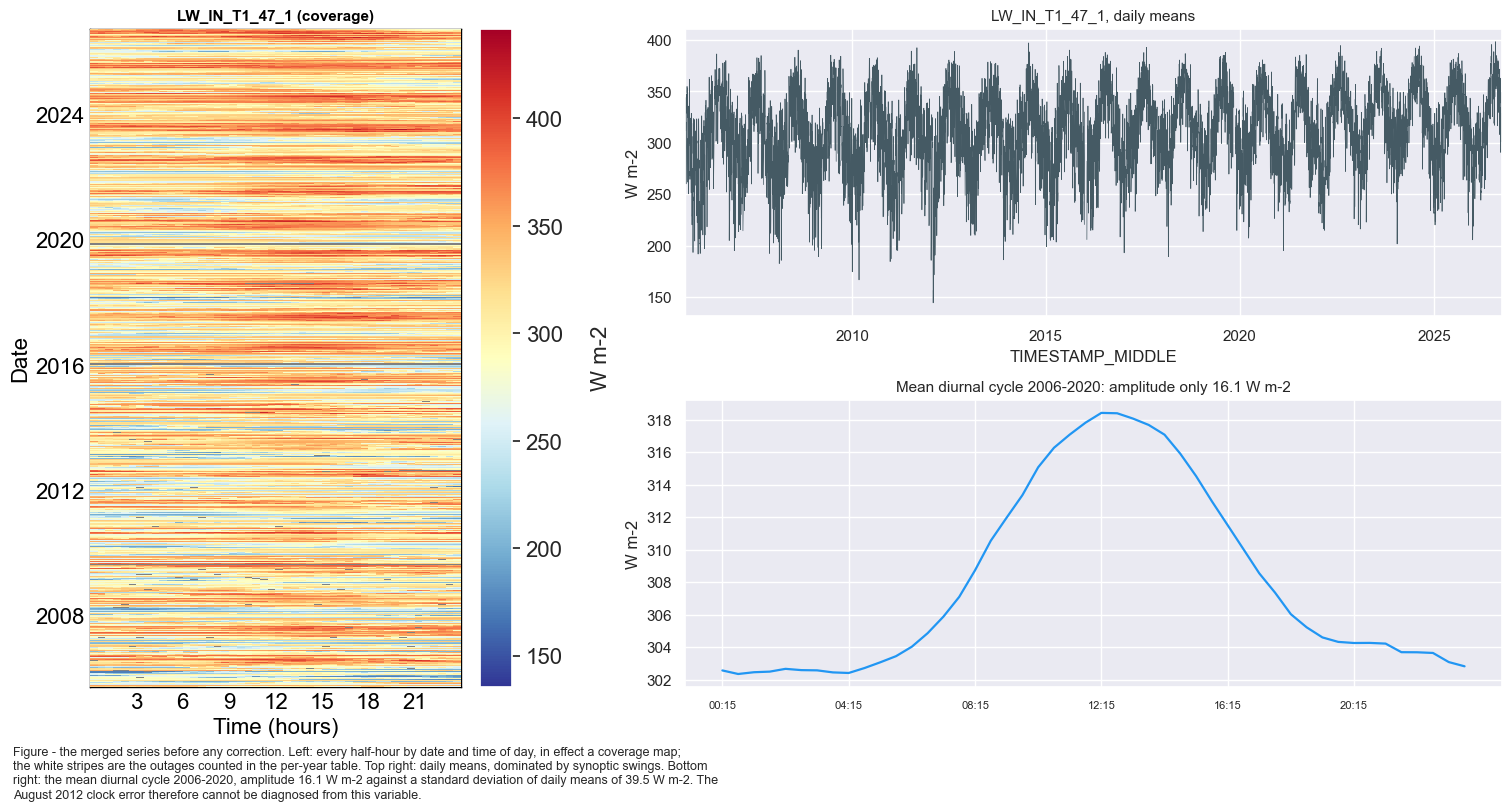

In [12]:
fig = plt.figure(figsize=(15, 8), dpi=100, layout='constrained')
gs = gridspec.GridSpec(2, 2, width_ratios=[1, 2.2], figure=fig)
ax_hm = fig.add_subplot(gs[:, 0])
ax_ts = fig.add_subplot(gs[0, 1])
ax_di = fig.add_subplot(gs[1, 1])

dv.plotting.HeatmapDateTime(series=lw_2005_2026[TARGET]).plot(
    ax=ax_hm, cb_digits_after_comma=0, zlabel='W m-2',
    format_style=dv.plotting.FormatStyle(title=f'{TARGET} (coverage)', title_fontsize=11))

lw_2005_2026[TARGET].resample('1D').mean().plot(ax=ax_ts, lw=0.5, color='#455A64')
ax_ts.set_ylabel('W m-2')
ax_ts.set_title(f'{TARGET}, daily means', fontsize=11)

_dc = lw_2005_2026.loc['2006':'2020', TARGET]
_dc = _dc.groupby(_dc.index.time).mean()
ax_di.plot(range(len(_dc)), _dc.values, color='#2196F3', lw=1.6)
ax_di.set_xticks(range(0, len(_dc), 8))
ax_di.set_xticklabels([str(t)[:5] for t in _dc.index[::8]], fontsize=8)
ax_di.set_ylabel('W m-2')
ax_di.set_title(f'Mean diurnal cycle 2006-2020: amplitude only '
                f'{_dc.max() - _dc.min():.1f} W m-2', fontsize=11)

_daily_sd = lw_2005_2026.loc['2006':'2020', TARGET].resample('1D').mean().std()
figcap(fig, f"the merged series before any correction. Left: every half-hour by date and time of "
            f"day, in effect a coverage map; the white stripes are the outages counted in the "
            f"per-year table. Top right: daily means, dominated by synoptic swings. Bottom right: "
            f"the mean diurnal cycle 2006-2020, amplitude {_dc.max() - _dc.min():.1f} W m-2 "
            f"against a standard deviation of daily means of {_daily_sd:.1f} W m-2. The August "
            f"2012 clock error therefore cannot be diagnosed from this variable.")

***

## ✴️ Corrections

### Timestamp shift in August 2012

**Info from fieldbook entry 17 Aug 2012:**
>   adjusted the logger date and time. On Servertime (Computer System Time) 17.08.2012 12:31.42 the loggertime was 16.08.2012 08:06:00. Synchronized time at 17.08.2012 11:40:00 servertime. The logger data aquisition on the moxa embedded was restarted

A logger clock error affects **every variable on that logger**: `LW_IN_T1_47_1` as well as
`SW_IN_T1_47_1`, `TA_T1_47_1`, `PPFD_IN_T1_47_1` and `PA_T1_47_1`. The same `+15.5 h` correction is
applied.

::: {.callout-warning title="This correction is applied on provenance, and cannot be verified from LW_IN itself"}
`01` checked the shift against **solar geometry**, `02` and `05` against an **independent NABEL
instrument**. `LW_IN` has neither: its diurnal cycle of some 16 W m-2 is small against synoptic
swings, there is no second pyrgeometer, and `TA_T1_47_1` shares the logger, so a clock error moves
both together.

The justification is **provenance**: the fieldbook documents a clock error on a shared logger, and
the shift is confirmed there by `SW_IN` against the sun and by `PA` against the NABEL barometer
(RMSE 0.324 -> 0.046 kPa on 11 August, notebook `05`). The plot below is not a validation.
:::

In [13]:
ISSUE_START = '2012-08-09 00:00'
ISSUE_END = '2012-08-17 00:00'
SHIFT_HOURS = 15.5

_df = lw_2005_2026.copy()
_before = _df[TARGET].copy()   # kept for the before/after plot

# Take the mis-stamped block and move it onto the correct time axis.
_series_shifted = _df.loc[ISSUE_START:ISSUE_END, TARGET].dropna()
_series_shifted.index = _series_shifted.index + pd.Timedelta(hours=SHIFT_HOURS)

# Clear everything between the start of the issue and the last shifted timestamp, then write the
# corrected values back. Same procedure as notebooks 01-03 and 05.
_df.loc[ISSUE_START:_series_shifted.index[-1], TARGET] = np.nan
_df.loc[_series_shifted.index, TARGET] = _series_shifted

print(f"shifted {len(_series_shifted):,} records by +{SHIFT_HOURS} h")
print(f"last shifted timestamp (corrected axis): {_series_shifted.index[-1]}")
print("\nApplied on provenance (shared logger). LW_IN cannot confirm or refute this on its own; "
      "see the note above.")

shifted 376 records by +15.5 h
last shifted timestamp (corrected axis): 2012-08-17 11:15:00

Applied on provenance (shared logger). LW_IN cannot confirm or refute this on its own; see the note above.


#### 📊 Plot: the August 2012 clock shift, before and after

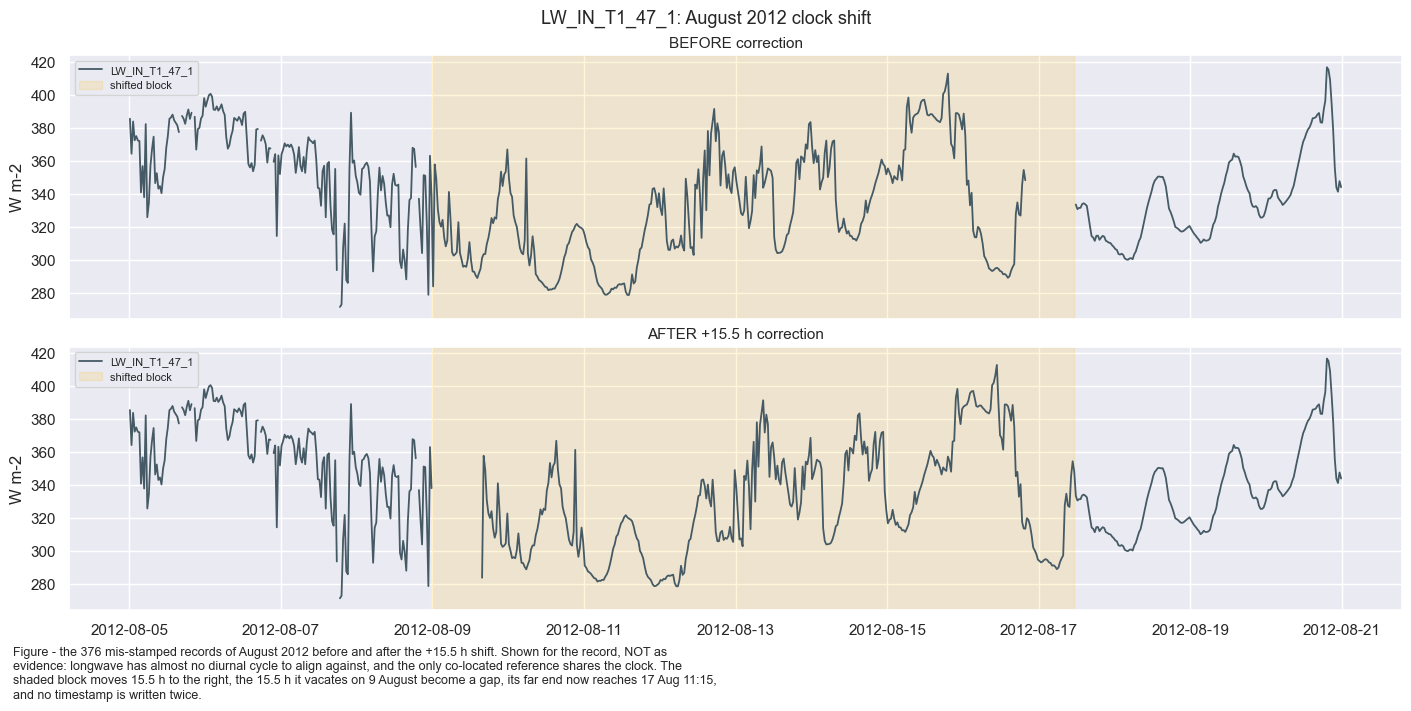

In [14]:
fig, axs = plt.subplots(nrows=2, figsize=(14, 7), dpi=100, layout='constrained',
                        sharex=True, sharey=True)
fig.suptitle(f'{TARGET}: August 2012 clock shift', fontsize=13)
_win = slice('2012-08-05', '2012-08-20')

for _ax, _series, _title in [(axs[0], _before, 'BEFORE correction'),
                             (axs[1], _df[TARGET], f'AFTER +{SHIFT_HOURS} h correction')]:
    _ax.plot(_series.loc[_win].index, _series.loc[_win].values, color='#455A64', lw=1.3,
             label=TARGET)
    _ax.axvspan(pd.Timestamp('2012-08-09'), pd.Timestamp('2012-08-17 11:15'),
                color='#FFC107', alpha=.15, label='shifted block')
    _ax.set_title(_title, fontsize=11)
    _ax.set_ylabel('W m-2')
    _ax.legend(fontsize=8, loc='upper left')

figcap(fig, f"the {len(_series_shifted):,} mis-stamped records of August 2012 before and after the "
            f"+{SHIFT_HOURS} h shift. Shown for the record, NOT as evidence: longwave has almost "
            f"no diurnal cycle to align against, and the only co-located reference shares the "
            f"clock. The shaded block moves {SHIFT_HOURS} h to the right, the {SHIFT_HOURS} h it "
            f"vacates on 9 August become a gap, its far end now reaches "
            f"{_series_shifted.index[-1]:%d %b %H:%M}, and no timestamp is written twice.")

In [15]:
lw_2005_2026 = _df.copy()

### Damaged periods in 2012

Notebooks `01`-`03` remove three 2012 windows: a tower power supply failure in late July / early
August, and storm damage and stressed cables in late October / early November, both documented:

> **09.08.2012** Fixed the power problem on the tower: replaced battery and replaced some fuses
> (there were many falsely placed or broken) and replaced the whole power supply
>
> **01.11.2012** Checked Forestfloor and Hut for broken sensors due to fallen trees and big branches
>
> **06.11.2012** checked all sensor cables. especialy the cables at the forest floor are sometimes
> strongly stressed. tried to unstress the cables

**`LW_IN` shows no internal sign of either fault** (table below): no repeated values, and an
emissivity inside the range of the clean weeks before. This null result is weak:

1. The emissivity check uses `TA_T1_47_1`, which shares the logger and is degraded in these windows
   (notebook `02`). A ratio of two suspect quantities can look normal while both are wrong.
2. `LW_IN` varies naturally over several hundred W m-2, so a bias of tens of W m-2 hides in the
   weather. `PA` exposed its fault only against an independent barometer agreeing to 0.04 kPa.
3. The `PA` fault was a **level error**, which this variable cannot see without a reference.

**Decision: the windows of `01`-`03` are removed**, including the 17-18 August transitional tail.
Data that a documented, logger-wide fault could have corrupted are discarded rather than kept on an
underpowered test; `SW_IN`, on the same system, is clearly affected. Notebook `05` narrowed the
window for `PA` because an independent barometer showed 28-29 October to be sound. No such positive
evidence exists here.

#### 📋 Table: the 2012 windows against a clean baseline

In [16]:
# Identical to notebooks 01-03, on the CORRECTED time axis (after the +15.5 h shift). Kept wide:
# LW_IN has no independent reference on which to narrow them (unlike PA in notebook 05).
BAD_WINDOWS_2012 = [
    ('2012-07-29 00:00', '2012-08-10 15:30'),  # tower power supply failure (fieldbook 09.08.2012)
    ('2012-08-17 15:30', '2012-08-18 00:00'),  # transitional tail after the last shifted value
    ('2012-10-28 00:00', '2012-11-10 00:00'),  # storm damage, stressed cables (fieldbook 01./06.11.2012)
]

# The null result, computed so that a re-run cannot silently disagree with the text.
_emis_2012 = emissivity(lw_2005_2026[TARGET])
_rows = []
for _lo, _hi, _lab in [('2012-06-01', '2012-07-25', 'baseline 1 Jun - 25 Jul'),
                       ('2012-07-29', '2012-08-10', 'window 1 (power supply)'),
                       ('2012-10-28', '2012-11-10', 'window 3 (storm damage)')]:
    _e = _emis_2012.loc[_lo:_hi].dropna()
    _v = lw_2005_2026.loc[_lo:_hi, TARGET].dropna()
    _rows.append({'period': _lab, 'n': len(_e),
                  'emissivity median': round(float(_e.median()), 3),
                  'emissivity min': round(float(_e.min()), 3),
                  'emissivity max': round(float(_e.max()), 3),
                  'outside 0.60-1.06 (%)': round(100 * float(((_e < 0.60) | (_e > 1.06)).mean()), 2),
                  'repeated values': int(_v.diff().eq(0).sum())})
tabcap("the two suspect 2012 windows seen from inside this variable, against the seven clean "
       "weeks before them. By every measure available without a reference they match the "
       "baseline, the null result discussed above")
display(pd.DataFrame(_rows).set_index('period'))

_before_n = int(lw_2005_2026[TARGET].notna().sum())
for _start, _end in BAD_WINDOWS_2012:
    lw_2005_2026.loc[_start:_end, TARGET] = np.nan
_removed = _before_n - int(lw_2005_2026[TARGET].notna().sum())
print(f"Removed {_removed:,} records from {TARGET} on provenance grounds "
      f"(left as gaps, nothing is filled).")

Table - the two suspect 2012 windows seen from inside this variable, against the seven clean weeks
before them. By every measure available without a reference they match the baseline, the null result
discussed above



,n,emissivity median,emissivity min,emissivity max,outside 0.60-1.06 (%),repeated values
period,,,,,,
baseline 1 Jun - 25 Jul,2619,0.861,0.667,1.031,0.0,0
window 1 (power supply),17,0.747,0.728,0.877,0.0,0
window 3 (storm damage),48,0.981,0.858,1.002,0.0,0


Removed 1,202 records from LW_IN_T1_47_1 on provenance grounds (left as gaps, nothing is filled).


#### 📊 Plot: the two 2012 windows removed

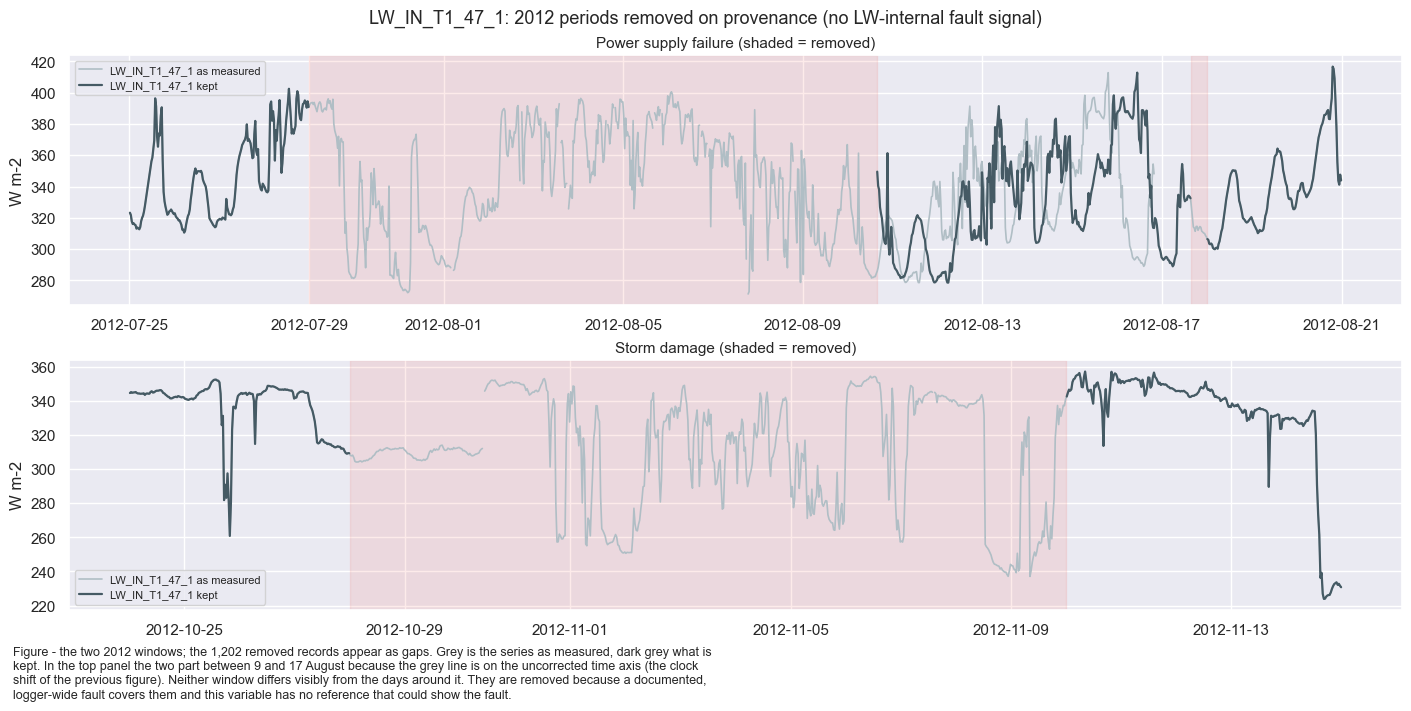

In [17]:
fig, axs = plt.subplots(nrows=2, figsize=(14, 7), dpi=100, layout='constrained')
fig.suptitle(f'{TARGET}: 2012 periods removed on provenance (no LW-internal fault signal)',
             fontsize=13)

for _ax, (_lo, _hi, _label) in zip(axs, [('2012-07-25', '2012-08-20', 'Power supply failure'),
                                         ('2012-10-24', '2012-11-14', 'Storm damage')]):
    _w = slice(_lo, _hi)
    _ax.plot(_before.loc[_w].index, _before.loc[_w].values, color='#B0BEC5', lw=1.2,
             label=f'{TARGET} as measured')
    _ax.plot(lw_2005_2026[TARGET].loc[_w].index, lw_2005_2026[TARGET].loc[_w].values,
             color='#455A64', lw=1.6, label=f'{TARGET} kept')
    for _s, _e in BAD_WINDOWS_2012:
        if pd.Timestamp(_s) <= pd.Timestamp(_hi) and pd.Timestamp(_e) >= pd.Timestamp(_lo):
            _ax.axvspan(pd.Timestamp(_s), pd.Timestamp(_e), color='#F44336', alpha=.10)
    _ax.set_title(f'{_label} (shaded = removed)', fontsize=11)
    _ax.set_ylabel('W m-2')
    _ax.legend(fontsize=8, loc='best')

figcap(fig, f"the two 2012 windows; the {_removed:,} removed records appear as gaps. Grey is the "
            f"series as measured, dark grey what is kept. In the top panel the two part between 9 "
            f"and 17 August because the grey line is on the uncorrected time axis (the clock shift "
            f"of the previous figure). Neither window differs visibly from the days around it. They "
            f"are removed because a documented, logger-wide fault covers them and this variable has "
            f"no reference that could show the fault.")

::: {.callout-note title="No nighttime zero-offset correction here"}
Notebooks `01` and `03` remove a nighttime zero-offset from `SW_IN` and `PPFD_IN`, whose true
nighttime value is zero. For `LW_IN` that correction would be **physically wrong**: downwelling
longwave is thermal emission and continues all night, typically 250-350 W m-2 at 03:00.

As in `05`, the trap from notebook `03` (a correction writing into gaps and relabelling fills as
measurements) **cannot occur**: the clock shift moves existing records, and the 2012 windows only
set values to `NaN`.
:::

***

## 🔎 Which sensor this is, and what the hardware changes did to it

The logger replacement of 21 January 2016 moved `TA_T1_47_1` by about 1.3 °C (notebook `02`), and
`LW_IN_T1_47_1` shares that acquisition system. The radiometer itself was replaced in December 2021.
Both dates have to be tested without a reference instrument.

Because a conversion error is proportional to `LW_net`, two nighttime statistics with opposite
sensitivities serve instead. They depend little on how cloudy a year was, provided it had both
clear and overcast nights:

- the **clear-sky envelope**, the 2nd percentile of nighttime `LW_net`, where a conversion error is
  largest;
- the **overcast ceiling**, the 95th percentile of nighttime apparent emissivity, where a conversion
  error is smallest. A low cloud base radiating at nearly air temperature pins it near 1.00, but
  only in months in which about 5 % or more of the night half-hours are overcast.

Summer 2026 did not meet that condition. It was exceptionally dry and clear: at MeteoSwiss Lägern,
relative humidity was 95 % or higher in 0.7-5.5 % of the half-hours of July to September, against
4-38 % in the same months of 2019-2025. The ceiling falls to 0.93-0.95 in those three months, below
the same months of every earlier year, and falls the same way when computed with the Lägern air temperature instead of
`TA_T1_47_1`. The drop is weather, not the instrument.

Scanned over the whole record, they show:

1. **One instrument, a Kipp & Zonen CNR1 (serial 020484), until December 2021**, with both
   radiometer channels converted by the **same** constant, which limits the absolute accuracy.
2. **The pyrgeometer's calibration factor was corrected on 7 June 2016**, from 10.03 to 12.83
   µV/W/m², and the series steps there. This is the one real inhomogeneity in the product.
3. **The January 2016 acquisition change did nothing.** The program installed then carries the old
   constant, and the step comes five months later.
4. **The December 2021 boundary moves the record by about half as much**, and the cause **cannot be
   determined**: two candidate causes coincide, and neither can be tested without a reference.

### Helpers for this section

The logger programs and the fieldbook are read in the notebook so that a re-run re-derives the
argument. Both are signed and this notebook is published, so every string taken from either passes
through the redaction used in notebooks `01`, `02`, `03` and `08`.

In [18]:
# --- Fieldbook and logger-program redaction ----------------------------------------------------
# Both sources name people and this notebook is published, so every string passes through
# redact_people() where it is flattened. Same map and rules as notebooks 01, 02, 03 and 08; the
# map lives beside the export, OUTSIDE this repository.
REDACT_MAP = Path(FIELDBOOK).with_name('redact_names.csv')
ALLOW_LIST = Path(FIELDBOOK).with_name('redact_allow.csv')


def unmapped_report_path(label: str) -> Path:
    """Where the unmapped-name candidates of one audit are written.

    Per label, because this notebook audits two sources: a single shared file would let the
    second audit overwrite the first one's findings.
    """
    _slug = re.sub(r'[^a-z0-9]+', '_', label.lower()).strip('_')
    return Path(FIELDBOOK).with_name(f'redact_unmapped_{_slug}.txt')


def load_redactions(path=None) -> dict:
    """Load the name -> pseudonym map.

    Raises if the map is missing. That is the point: carrying on with redaction quietly disabled
    prints real names into a published page and looks exactly like success.
    """
    path = REDACT_MAP if path is None else Path(path)
    if not path.is_file():
        raise FileNotFoundError(
            f"the redaction map is missing: {path}. Without it the names these files record would "
            f"print unredacted. Restore the file rather than skipping this.")
    tab = pd.read_csv(path, encoding='utf-8')
    missing = {'name', 'pseudonym'}.difference(tab.columns)
    if missing:
        raise ValueError(f"{path}: missing column(s) {sorted(missing)}.")
    pairs = {str(n).strip(): str(p).strip()
             for n, p in zip(tab['name'], tab['pseudonym']) if str(n).strip()}
    if not pairs:
        raise ValueError(f"{path}: holds no usable name -> pseudonym pairs.")
    return pairs


REDACTIONS = load_redactions()
# Longest surface form first, so a bare surname cannot corrupt a double-barrelled one that starts
# with it. Lookarounds rather than \b, because some forms end in an initial.
_REDACT_RX = re.compile(r'(?<!\w)(' + '|'.join(re.escape(n) for n in
                                               sorted(REDACTIONS, key=len, reverse=True))
                        + r')(?!\w)')


def redact_people(s) -> str:
    """Replace every mapped name with its stable pseudonym."""
    return _REDACT_RX.sub(lambda m: REDACTIONS[m.group(1)], str(s))


def strip_html(text) -> str:
    """Flatten one GIN fieldbook entry to plain text, with the people it names redacted."""
    flat = html.unescape(re.sub(r'<[^>]+>', ' ', str(text)))
    return redact_people(re.sub(r'\s+', ' ', flat).strip())


_NAME_TOKEN = r"[A-ZÄÖÜ][\wÄÖÜäöüß'-]{1,20}"
_NAME_UNIT = _NAME_TOKEN + r'(?:\s+' + _NAME_TOKEN + r'){0,2}'
_NAME_SHAPES = (
    re.compile(r'\((' + _NAME_UNIT + r'(?:\s*[,+&]\s*' + _NAME_UNIT + r')*)\s*'
               r'(?:\d{1,2}\.\d{1,2}\.\d{4})?\)'),
    re.compile(r'(?:with|by|durch|von|gemaess)\s+(' + _NAME_TOKEN + r'(?:\s+' + _NAME_TOKEN + r')?)'),
)


def audit_unmapped_names(texts, label='fieldbook', write_report: bool = True) -> int:
    """Raise if any name-shaped token survived redaction.

    A newer export can name someone the map has never seen. Candidates are never printed - an
    exception message is stored in a notebook like any other output - so they go to a file beside
    the map and only the count is shown.
    """
    allow = set(pd.read_csv(ALLOW_LIST, encoding='utf-8')['term'].astype(str).str.strip())
    found = {}
    for _t in texts:
        for _rx in _NAME_SHAPES:
            for _m in _rx.finditer(str(_t)):
                for _tok in re.findall(_NAME_TOKEN, _m.group(1)):
                    if _tok.isupper() or any(ch.isdigit() for ch in _tok) or _tok in allow:
                        continue
                    found[_tok] = found.get(_tok, 0) + 1
    if found:
        _report = unmapped_report_path(label)
        if write_report:
            _report.write_text(
                '\n'.join(f'{n}\t{t}' for t, n in sorted(found.items(), key=lambda kv: -kv[1])),
                encoding='utf-8')
        raise ValueError(
            f"{label}: {len(found)} name-shaped token(s) survived redaction. They are deliberately "
            f"NOT shown here - see {_report}. Add the people to redact_names.csv and the "
            f"technical terms to redact_allow.csv, then re-run.")
    print(f"  {label}: no unmapped name-shaped tokens ({len(allow)} allowlisted terms)")
    return 0


def program_excerpt(path, pattern: str, before: int = 6, after: int = 4, expect: int = 1) -> str:
    """The lines of a logger program around `pattern`, redacted.

    Only the matched instruction is returned, never the file header: these programs are signed by
    their authors. Raises unless the pattern matches exactly `expect` times. Both directions
    matter: no match reads as 'the program does not measure this', and an over-broad pattern
    quietly prints the wrong instruction next to the argument it is supposed to support.
    """
    lines = Path(path).read_text(encoding='latin-1').splitlines()
    blocks = []
    for i, line in enumerate(lines):
        if re.search(pattern, line):
            lo, hi = max(0, i - before), min(len(lines), i + after + 1)
            blocks.append('\n'.join(lines[lo:hi]))
    if len(blocks) != expect:
        raise ValueError(f"{Path(path).name}: {pattern!r} matched {len(blocks)} time(s), expected "
                         f"{expect}. The program layout has changed, the wrong file is configured, "
                         f"or the pattern is not specific enough.")
    return redact_people('\n\n'.join(blocks))


def calibration_constants(excerpt: str) -> dict:
    """The multiplier and offset of one measurement instruction, parsed from its own text.

    The two program languages write the same two numbers differently - the CR10X lists them as
    numbered parameters, the CR1000 as positional arguments - so each is matched on its own shape.
    Raises if either number cannot be found, because a silently empty dict would make the
    comparison below pass by having nothing to disagree about. Pass an excerpt holding exactly one
    instruction: with two, the first one wins and the answer is about the wrong channel.
    """
    if 'Mult' in excerpt:                                    # CR10X parameter listing
        mult = re.search(r'^\s*\d+:\s*([\d.]+)\s+Mult', excerpt, re.M)
        offset = re.search(r'^\s*\d+:\s*([\d.]+)\s+Offset', excerpt, re.M)
    else:                                                    # CR1000 VoltDiff(...) call
        call = re.search(r'VoltDiff\s*\(([^)]*)\)', excerpt)
        args = [a.strip() for a in call.group(1).split(',')] if call else []
        mult = re.match(r'([\d.]+)$', args[-2]) if len(args) >= 2 else None
        offset = re.match(r'([\d.]+)$', args[-1]) if len(args) >= 2 else None
    if not (mult and offset):
        raise ValueError("could not parse a multiplier and an offset from the instruction - the "
                         "program language or the layout has changed")
    return {'multiplier': float(mult.group(1)), 'offset': float(offset.group(1))}

In [19]:
# Every failure path of the helpers is exercised before anything is read.
try:
    program_excerpt(PROGRAM_AFTER, r'ThisPatternIsNotInAnyLoggerProgram')
except ValueError as _exc:
    print(f"OK, program_excerpt raised on a pattern that does not occur: {_exc}")
else:
    raise AssertionError("(!) program_excerpt accepted a pattern that does not occur.")

# 'Ada Lovelace' is an invented name. The control writes no report, so the real one is kept.
try:
    audit_unmapped_names(['12.05.2019 (Ada Lovelace) replaced the logger battery'],
                         'positive control', write_report=False)
except ValueError:
    print("OK, the unknown-name net fired on a name that is not in the map")
else:
    raise AssertionError("(!) the unknown-name net did not fire on an unmapped name.")

# The constant parser must refuse an instruction it cannot read.
try:
    calibration_constants("19:  Volt (Diff) (P2) ;Messung von Lin\n 1: 1        Reps")
except ValueError as _exc:
    print(f"OK, calibration_constants raised on an instruction with no constants: {_exc}")
else:
    raise AssertionError("(!) calibration_constants accepted an instruction carrying no constants.")

OK, program_excerpt raised on a pattern that does not occur: CH-LAE_iDL_T1_47_1.CR1: 'ThisPatternIsNotInAnyLoggerProgram' matched 0 time(s), expected 1. The program layout has changed, the wrong file is configured, or the pattern is not specific enough.
OK, the unknown-name net fired on a name that is not in the map
OK, calibration_constants raised on an instruction with no constants: could not parse a multiplier and an offset from the instruction - the program language or the layout has changed


### 1️⃣ One instrument, and one constant for both of its radiometer channels

The two constants of the **longwave** instruction are parsed from every surviving logger program on
every run. The shortwave instruction is parsed alongside, because the relation between the two is
the point of this step.

#### 📋 Table: conversion constants per logger program

In [20]:
# CR10X programs oldest first, then the CR1000 program installed at the 2016 changeover. Each file
# gives a wide excerpt for display (both radiometer channels) and a single-instruction one for the
# parser, because calibration_constants() reads the first instruction it finds.
LW_CONSTANTS, SW_CONSTANTS = {}, {}
_excerpts = []

print("=" * 78)
print("BEFORE 2016: the CR10X programs")
print("=" * 78)
for _p in PROGRAMS_BEFORE:
    _wide = program_excerpt(_p, r'Messung von Lin', before=13, after=6)
    _excerpts.append(_wide)
    LW_CONSTANTS[Path(_p).name] = calibration_constants(
        program_excerpt(_p, r'Messung von Lin', before=0, after=6))
    SW_CONSTANTS[Path(_p).name] = calibration_constants(
        program_excerpt(_p, r'Messung von Kin', before=0, after=6))
    print(f"\n--- {Path(_p).name}")
    print(_wide)

print("\n" + "=" * 78)
print(f"AFTER 2016:  {Path(PROGRAM_AFTER).name}")
print("=" * 78)
_cr1000_wide = program_excerpt(PROGRAM_AFTER, r'VoltDiff\(LW_IN_T1_47_1', before=7, after=0)
_excerpts.append(_cr1000_wide)
LW_CONSTANTS[Path(PROGRAM_AFTER).name] = calibration_constants(
    program_excerpt(PROGRAM_AFTER, r'VoltDiff\(LW_IN_T1_47_1', before=0, after=0))
SW_CONSTANTS[Path(PROGRAM_AFTER).name] = calibration_constants(
    program_excerpt(PROGRAM_AFTER, r'VoltDiff\(SW_IN_T1_47_1', before=0, after=0))
print(_cr1000_wide)

# The programs are signed: redaction inside program_excerpt, the unknown-name audit here.
audit_unmapped_names(_excerpts, 'logger programs')

tabcap("the conversion each surviving logger program applies to the two radiometer channels. "
       "The channels have different sensitivities, yet every program converts both with the "
       "same constant")
_const = pd.DataFrame({'LW_IN multiplier': {k: v['multiplier'] for k, v in LW_CONSTANTS.items()},
                       'LW_IN offset': {k: v['offset'] for k, v in LW_CONSTANTS.items()},
                       'SW_IN multiplier': {k: v['multiplier'] for k, v in SW_CONSTANTS.items()},
                       'implied sensitivity (uV/W/m2)':
                           {k: round(1000 / v['multiplier'], 3) for k, v in LW_CONSTANTS.items()}})
_const.index.name = 'logger program'
display(_const)

_lw_mults = {v['multiplier'] for v in LW_CONSTANTS.values()}
_lw_offs = {v['offset'] for v in LW_CONSTANTS.values()}
print(f"\ndistinct LW_IN multipliers across all {len(LW_CONSTANTS)} programs: {sorted(_lw_mults)}")
print(f"distinct LW_IN offsets:    {sorted(_lw_offs)}")
assert len(_lw_mults) == 1 and _lw_offs == {0.0}, (
    "the surviving programs no longer all apply one conversion to the longwave channel - the "
    "argument that the January 2016 changeover cannot have moved this series has to be re-derived")

# The point of this step: the pyrgeometer was converted with the PYRANOMETER's factor.
assert all(LW_CONSTANTS[_k]['multiplier'] == SW_CONSTANTS[_k]['multiplier'] for _k in LW_CONSTANTS), (
    "the two radiometer channels no longer share a multiplier in every program, so the absolute-"
    "accuracy statement below no longer describes these files")
SENSITIVITY_PROGRAM = 1000 / max(_lw_mults)
print(f"implied sensitivity on both channels: {SENSITIVITY_PROGRAM:.2f} uV/W/m2, which is the "
      f"CNR1 calibration factor the programs' own comments give for the instrument")

BEFORE 2016: the CR10X programs

--- LAEGEREN.20050818.CSI
;-----------------------------------------------------------------------
; Net Radiometer CNR1 from NABEL-Station,sn: 020484, factor=10.03uV/W/m2
;-----------------------------------------------------------------------


18:  Volt (Diff) (P2) ;Messung von Kin
 1: 1        Reps
 2: 33       25 mV 50 Hz Rejection Range
 3: 3        DIFF Channel
 4: 23       Loc [ Kin       ]
 5: 99.7009  Mult
 6: 0.0      Offset

19:  Volt (Diff) (P2) ;Messung von Lin
 1: 1        Reps
 2: 32       7.5 mV 50 Hz Rejection Range
 3: 4        DIFF Channel
 4: 25       Loc [ Lin       ]
 5: 99.7009  Mult
 6: 0.0      Offset

--- LAEGEREN.20050914.CSI
;-----------------------------------------------------------------------
; Net Radiometer CNR1 from NABEL-Station,sn: 020484, factor=10.03uV/W/m2
;-----------------------------------------------------------------------


18:  Volt (Diff) (P2) ;Messung von Kin
 1: 1        Reps
 2: 33       25 mV 50 Hz Re

,LW_IN multiplier,LW_IN offset,SW_IN multiplier,implied sensitivity (uV/W/m2)
logger program,,,,
LAEGEREN.20050818.CSI,99.7009,0.0,99.7009,10.03
LAEGEREN.20050914.CSI,99.7009,0.0,99.7009,10.03
LAEGEREN.20060524.csi,99.7009,0.0,99.7009,10.03
CH-LAE_iDL_T1_47_1.CR1,99.7009,0.0,99.7009,10.03



distinct LW_IN multipliers across all 4 programs: [99.7009]
distinct LW_IN offsets:    [0.0]
implied sensitivity on both channels: 10.03 uV/W/m2, which is the CNR1 calibration factor the programs' own comments give for the instrument


Both acquisition systems read **the same instrument**, a Kipp & Zonen CNR1, serial 020484, and
convert **both radiometer channels with one constant**, the 10.03 µV/W/m² named in the programs'
comments, which belongs to the pyranometer.

A CNR1's sensors are calibrated individually: for the successor instrument the site record lists
13.89 µV/W/m² for shortwave and 10.85 for longwave, 28 % apart. Using the pyranometer's factor
scales the pyrgeometer's net signal by their ratio, an error proportional to `LW_net` rather than a
constant offset. The next step shows that it was found and corrected mid-record.

::: {.callout-note title="What the programs cover, and what they do not"}
Three CR10X programs carry this measurement (August 2005 to May 2006), and the CR1000 program dates
from January 2016. **None survives from May 2006 to January 2016, or after it**, including the
program that made the change reported here. The programs fix two endpoints; the rest comes from the
data and the fieldbook.
:::

### 2️⃣ What the maintenance record holds for this radiometer

The statistics below were scanned over the whole record before the fieldbook was consulted. The
fieldbook is filtered on the **device columns and the free text**, because entries about the
radiometer are often filed under the logger.

#### 📋 Table: fieldbook entries naming the radiometer

In [21]:
fb = pd.read_csv(FIELDBOOK)
fb['Date'] = pd.to_datetime(fb['Date'], format='%d.%m.%Y', errors='coerce')
fb['text'] = fb['Text'].apply(strip_html)
audit_unmapped_names(fb['text'], 'fieldbook entries')
print(f"fieldbook: {len(fb):,} entries, {fb['Date'].min().date()} -> {fb['Date'].max().date()}")

_dev = fb[['Device Name', 'Device Model']].astype(str).agg(' '.join, axis=1)
_RADIOMETER = r'CNR1|CNR4|net ?radiom|NetRad|Kipp|pyrgeo|LW_IN|Eichfaktor'
_by_device = _dev.str.contains(_RADIOMETER, case=False, regex=True, na=False)
_by_text = fb['text'].str.contains(_RADIOMETER, case=False, regex=True, na=False)
# 1 January 2016 and the other backdated rows are the GIN inventory import, not events.
hits = fb[(_by_device | _by_text) & (fb['Date'] != '2016-01-01')].sort_values('Date')
assert len(hits) > 0, "no radiometer entries at all - is this the right export?"
print(f"entries naming the radiometer: {len(hits)} "
      f"({int(_by_device.sum())} by device column, {int(_by_text.sum())} by free text)")


def fragment(text, pattern=_RADIOMETER, width=70) -> str:
    """The part of one entry that names the radiometer, rather than its first hundred characters.

    Several of these entries are whole-day visit reports in which the instrument is named once,
    halfway through; truncating from the start shows the drive to the site instead.
    """
    _m = re.search(pattern, str(text), re.I)
    if not _m:
        return str(text)[:2 * width]
    _lo, _hi = max(0, _m.start() - width), min(len(str(text)), _m.end() + width)
    return ('...' if _lo else '') + str(text)[_lo:_hi] + ('...' if _hi < len(str(text)) else '')


tabcap("every fieldbook entry naming the tower radiometer, shown around the matching words. Rows "
       "with 'na' device columns were found by the free text alone; the two most important "
       "entries are among them, so the device filter alone is not enough")
_show = hits[['Date', 'Device Model', 'Operation Tag', 'text']].copy()
_show['Date'] = _show['Date'].dt.date
_show['text'] = _show['text'].apply(fragment)
with pd.option_context('display.max_colwidth', 150, 'display.max_rows', 60):
    display(_show.set_index('Date'))

  fieldbook entries: no unmapped name-shaped tokens (58 allowlisted terms)
fieldbook: 2,133 entries, 2003-10-24 -> 2026-10-16
entries naming the radiometer: 29 (9 by device column, 25 by free text)
Table - every fieldbook entry naming the tower radiometer, shown around the matching words. Rows
with 'na' device columns were found by the free text alone; the two most important entries are among
them, so the device filter alone is not enough



,Device Model,Operation Tag,text
Date,,,
2011-06-03,na,na,...tation was necessary 07.10.2008 (person 07) Meteo Replaced relais for CNR1 (Meteo-logger CR10X on tower) 01.10.2008 (person 22) QCLAS-system mo...
2016-01-08,na,na,...struments A100LK cup anemometer wwith SN 16697 installed a new direct Kipp&Zonen par ( SN:) sensor and replaced the reflective par ( SN:) on th...
2016-05-26,na,na,...ule (after the IRGA cell) Radiation boom in from 9:30 to 9:50 checked CNR1 NetRadiometer (NABEL) connection to our tower logger. all correct. r...
2016-05-27,na,na,...am to the logger again and tried some minor program changes to avoid skipped system scans –> not yet suceeded
2016-05-30,na,na,.... Data is saved as data table. Checked function of the logger. Still skipped system scans and 2 skipped scans. Probalby during referencing. The...
2016-06-07,na,na,"...riables: WD_VANE_T1_47_1_AVG, WD_VANE_T1_47_1_Std New variable Public LW_IN_COR_T1_47_1 and LW_OUT_COR_T1_47_1 (not in variabel list) values wi..."
2016-06-17,na,na,...his scritp is running in sequential mode again. Thias leads to minor skipped system scans but should solve most of the other timing issues. The...
2016-12-12,na,na,"...ter of the li7200, reinstalled filter and inlet tube cleaned BF3, and Kipp&Zonen PAR lite. 15:00 set T1B3 boom back cleaned the profile windson..."
2018-05-29,CNR1,na,Added device to site.


In [22]:
# The entry this section rests on, printed in full. Found by its text rather than its date, so a
# re-export that moved the date still finds it.
_cal_entries = fb[fb['text'].str.contains(r'calibration factor changed', case=False, na=False)]
assert len(_cal_entries) >= 1, (
    "the fieldbook no longer records a change of the radiometer calibration factor - the whole of "
    "step 3 rests on this entry and must be re-derived")
_cal = _cal_entries.sort_values('Date').iloc[0]
CAL_ENTRY_DATE = _cal['Date']
print(f"--- {CAL_ENTRY_DATE.date()}")
print(textwrap.fill(_cal['text'], 110))

# The two factors are parsed from the entry, so they cannot drift from the record.
_m = re.search(r'calibration factor changed from ([\d.]+) to ([\d.]+)', _cal['text'], re.I)
assert _m, "the calibration-factor sentence no longer has the shape this cell parses"
SENSITIVITY_OLD, SENSITIVITY_NEW = float(_m.group(1)), float(_m.group(2))
CAL_RATIO_DOCUMENTED = SENSITIVITY_OLD / SENSITIVITY_NEW
print(f"\npyrgeometer calibration factor: {SENSITIVITY_OLD} -> {SENSITIVITY_NEW} uV/W/m2")
print(f"the net longwave signal of the earlier era is therefore too large by "
      f"{100 * (1 / CAL_RATIO_DOCUMENTED - 1):.1f} %, i.e. it has to be multiplied by "
      f"{CAL_RATIO_DOCUMENTED:.4f} to be on the later era's calibration")
assert abs(SENSITIVITY_OLD - SENSITIVITY_PROGRAM) < 0.01, (
    "the factor the entry replaces is no longer the one the logger programs apply, so the entry "
    "and the programs are no longer describing the same measurement")
assert pd.Timestamp(CAL_ENTRY_DATE).year == 2016, (
    "the calibration-factor entry has moved out of 2016 - re-derive the era boundaries below")

--- 2016-06-07
07.06.2016 (person 01) downloaded manually the logger data from logger CH-LAE_iDL_T1_47_1 to the embedded and
saved the loggernet tables to the data upload folder uploaded new loggerprogram CH-LAE_CR1000_T1_47_1_20160606
to the logger. The program corrects following bugs: New variable windvector replaces 'Average
(1,WD_VANE_T1_47_1,IEEE4,False)' which clearly leads to incorrect values. New variables:
WS_CUP_SCALAR_T1_47_1_WVc(1), WS_CUP_SCALAR_T1_47_1_WVc(2), WS_CUP_SCALAR_T1_47_1_WVc(3),
WS_CUP_SCALAR_T1_47_1_WVc(4). Removed variables: WD_VANE_T1_47_1_AVG, WD_VANE_T1_47_1_Std New variable Public
LW_IN_COR_T1_47_1 and LW_OUT_COR_T1_47_1 (not in variabel list) values with boltzmann correction function. New
variables in table: , LW_IN_COR_T1_47_1_Avg, LW_OUT_COR_T1_47_1_Avg, LW_IN_COR_T1_47_1_Std,
LW_OUT_COR_T1_47_1_Std. Keeping LW_IN_T1_47_1 and LW_OUT_T1_47_1 besides this variable actually should be
named LW_IN_RAW_T1_47_1 and LW_IN_RAW_T1_47_1 according to variable nami

The entry of **7 June 2016** introduces `LW_IN_COR_T1_47_1`, the variable `diive` reads from 2022,
and corrects the pyrgeometer's calibration factor from the pyranometer's 10.03 µV/W/m² to the
instrument's own 12.83, on information from the institution that owns the radiometer.

That correction is a **change to the measurement**. Before it, the sensitivity used is 28 % too
small, so the net longwave signal is 28 % too large in magnitude. The next step measures this.

### 3️⃣ The June 2016 calibration change, measured in the data

A calibration error moves the clear-sky envelope but not the overcast ceiling, and it scales the
envelope by the **same factor at every percentile**, which a change in the weather does not do. Both
statistics are computed per month and per year over the whole record; yearly values stop at
`LAST_FULL_YEAR`.

In [23]:
# The two statistics, on nighttime records with measured TA. The helpers raise rather than return
# a percentile built from a handful of half-hours.
LW_FINAL = lw_2005_2026[TARGET]
LWNET_NIGHT = net_longwave(LW_FINAL).where(NIGHT)
EMIS_NIGHT = emissivity(LW_FINAL).where(NIGHT)
CLEAR_Q = 0.02          # the clear-sky envelope
OVERCAST_Q = 0.95       # the overcast ceiling
MIN_PER_MONTH = 200


def monthly_q(series: pd.Series, q: float, minrec: int = MIN_PER_MONTH) -> pd.Series:
    """Monthly quantile of `series`, months with fewer than `minrec` records dropped."""
    s = series.dropna()
    v, n = s.resample('MS').quantile(q), s.resample('MS').count()
    out = v[n >= minrec]
    if out.empty:
        raise ValueError(f"no month reaches {minrec} records - the statistic has no support")
    return out


def yearly_q(series: pd.Series, q: float, minrec: int = MIN_PER_MONTH,
             minmonths: int = 10) -> pd.Series:
    """Yearly quantile, taken per calendar month and then averaged over months.

    Month-matched on purpose: this variable has a strong seasonal cycle in both statistics, so a
    year short of a winter must not be compared against one that is not. Years after
    LAST_FULL_YEAR are partial and excluded.
    """
    s = series.dropna()
    s = s[s.index.year <= LAST_FULL_YEAR]
    v = s.groupby([s.index.year, s.index.month]).quantile(q)
    v.index.names = ['year', 'month']
    n = s.groupby([s.index.year, s.index.month]).count()
    v = v[n >= minrec]
    keep = v.groupby(level=0).count()
    out = v.groupby(level=0).mean()
    out.index.name = 'YEAR'
    out = out[keep >= minmonths]
    if out.empty:
        raise ValueError(f"no year reaches {minmonths} months of at least {minrec} records")
    return out


def step_at(series: pd.Series, year: int, span: int = 3) -> float:
    """Percentage change of a yearly statistic across `year`, over `span` years either side.

    The candidate year itself is excluded from both sides: a change inside a year belongs to
    neither era. Returns nan when either side is thin, so a year at the edge of the record cannot
    win a scan by having almost no data behind it.
    """
    pre = series.reindex(range(year - span, year)).dropna()
    post = series.reindex(range(year + 1, year + 1 + span)).dropna()
    if len(pre) < 2 or len(post) < 2:
        return float('nan')
    return 100 * (post.mean() / pre.mean() - 1)


def matched_ratio(monthly: pd.Series, months, years_before, years_after) -> dict:
    """The clear-sky envelope over the same calendar months, before and after a date.

    Month-matched and close in time, which is what makes it a test of a date rather than of a
    decade: the same calendar months are compared, so the seasonal cycle cancels, and the two
    windows are adjacent, so a slow trend has little room to act. A candidate date inside a year
    is tested by splitting that year - the months before it against the same months of earlier
    years, and the months after it against the same months of earlier years.
    """
    a = monthly[monthly.index.month.isin(months) & monthly.index.year.isin(years_before)]
    b = monthly[monthly.index.month.isin(months) & monthly.index.year.isin(years_after)]
    if len(a) < len(months) or len(b) < max(1, int(0.8 * len(months))):
        raise ValueError(f"months {list(months)}: {len(a)} before and {len(b)} after reach the "
                         f"record threshold, too few to compare")
    return {'months compared': f'{len(a)} vs {len(b)}',
            'before (W m-2)': round(float(a.median()), 1),
            'after (W m-2)': round(float(b.median()), 1),
            'ratio': round(float(b.median() / a.median()), 4)}


def placebo_ratios(monthly: pd.Series, months, boundaries, span: int = 3) -> pd.Series:
    """The same statistic at every year of the record, on windows holding no known boundary.

    This is what the boundary values are read against. A year whose window straddles one of
    `boundaries` is dropped, because it would be reporting the very thing being tested.
    """
    out = {}
    for _y in range(int(monthly.index.year.min()) + span, int(monthly.index.year.max()) + 1):
        if any(_y - span <= pd.Timestamp(_b).year <= _y for _b in boundaries):
            continue
        try:
            out[_y] = matched_ratio(monthly, months, range(_y - span, _y), [_y])['ratio']
        except ValueError:
            continue
    if len(out) < 5:
        raise ValueError(f"only {len(out)} quiet years available - the reference distribution "
                         f"would be built on too little to mean anything")
    return pd.Series(out).sort_index()


ENVELOPE_M = monthly_q(LWNET_NIGHT, CLEAR_Q)
ENVELOPE_Y = yearly_q(LWNET_NIGHT, CLEAR_Q)
CEILING_Y = yearly_q(EMIS_NIGHT, OVERCAST_Q)
print(f"nighttime records with a measured TA: {int(LWNET_NIGHT.notna().sum()):,}")
print(f"months in the envelope series: {len(ENVELOPE_M)}   years: {len(ENVELOPE_Y)}")

nighttime records with a measured TA: 173,753
months in the envelope series: 253   years: 20


In [24]:
# Negative controls: each helper must refuse to return a number from almost no data.
for _fn, _kw, _why in [(monthly_q, dict(minrec=10 ** 7), 'no month reaches the record threshold'),
                       (yearly_q, dict(minrec=10 ** 7), 'no year reaches the record threshold'),
                       (yearly_q, dict(minmonths=13), 'no year has thirteen calendar months')]:
    try:
        _fn(LWNET_NIGHT, CLEAR_Q, **_kw)
    except ValueError as _exc:
        print(f"OK, {_fn.__name__} raised on '{_why}': {_exc}")
    else:
        raise AssertionError(f"(!) {_fn.__name__} accepted a threshold no data can meet ({_why}).")

assert np.isnan(step_at(ENVELOPE_Y, 1990)), "(!) step_at returned a number for a year off the record"
assert np.isnan(step_at(ENVELOPE_Y, int(ENVELOPE_Y.index.max()))), \
    "(!) step_at returned a number for the last year, which has no years after it"
print("OK, step_at returns nan where one side of the comparison does not exist")

try:
    matched_ratio(ENVELOPE_M, [7, 8, 9], [1990, 1991, 1992], [2016])
except ValueError as _exc:
    print(f"OK, matched_ratio raised on years the record does not cover: {_exc}")
else:
    raise AssertionError("(!) matched_ratio accepted a window with no data before it.")

try:
    placebo_ratios(ENVELOPE_M, [7], [f'{_y}-01-01' for _y in
                                     range(2006, int(ENVELOPE_M.index.year.max()) + 1)])
except ValueError as _exc:
    print(f"OK, placebo_ratios raised when every year was declared a boundary: {_exc}")
else:
    raise AssertionError("(!) placebo_ratios built a reference distribution out of nothing.")

OK, monthly_q raised on 'no month reaches the record threshold': no month reaches 10000000 records - the statistic has no support
OK, yearly_q raised on 'no year reaches the record threshold': no year reaches 10 months of at least 10000000 records
OK, yearly_q raised on 'no year has thirteen calendar months': no year reaches 13 months of at least 200 records
OK, step_at returns nan where one side of the comparison does not exist
OK, matched_ratio raised on years the record does not cover: months [7, 8, 9]: 0 before and 3 after reach the record threshold, too few to compare
OK, placebo_ratios raised when every year was declared a boundary: only 0 quiet years available - the reference distribution would be built on too little to mean anything


#### 📋 Table: era ratio at five clear-sky percentiles

In [25]:
# A calibration error scales LW_net, so the era ratio must be the same at every percentile of the
# clear-sky tail. 2016 holds both eras and is excluded; from 2022 the instrument changes again.
ERA_BEFORE, ERA_AFTER = (2006, 2015), (2017, 2021)
tabcap("the clear-sky envelope of the eras either side of the June 2016 entry, at five nighttime "
       "percentiles. A calibration error gives the same ratio in every row; weather has no reason "
       "to")
_rows = []
for _q in (0.01, 0.02, 0.05, 0.10, 0.20):
    _y = yearly_q(LWNET_NIGHT, _q)
    _a, _b = _y.loc[ERA_BEFORE[0]:ERA_BEFORE[1]].mean(), _y.loc[ERA_AFTER[0]:ERA_AFTER[1]].mean()
    _rows.append({'percentile': f'p{int(100 * _q):02d}',
                  f'{ERA_BEFORE[0]}-{ERA_BEFORE[1]} (W m-2)': round(float(_a), 1),
                  f'{ERA_AFTER[0]}-{ERA_AFTER[1]} (W m-2)': round(float(_b), 1),
                  'ratio': round(float(_b / _a), 4)})
_era_tab = pd.DataFrame(_rows).set_index('percentile')
display(_era_tab)

CAL_RATIO_MEASURED = float(_era_tab['ratio'].mean())
_spread = float(_era_tab['ratio'].max() - _era_tab['ratio'].min())
print(f"measured ratio: {CAL_RATIO_MEASURED:.4f}, the same to within {_spread:.4f} across a "
      f"twentyfold range of percentiles")
print(f"documented ratio {SENSITIVITY_OLD}/{SENSITIVITY_NEW} = {CAL_RATIO_DOCUMENTED:.4f}")
print(f"difference: {CAL_RATIO_MEASURED - CAL_RATIO_DOCUMENTED:+.4f}")

# Three assertions, and they say different things.
assert _spread < 0.03, (
    "the era ratio is no longer the same at every percentile of the clear-sky tail, so it is no "
    "longer the signature of a multiplicative change and this step must be re-derived")
assert CAL_RATIO_MEASURED < 0.90, (
    "the clear-sky envelope no longer shrinks across June 2016 - the step this notebook reports, "
    "and the flag it exports, would then be describing something that is not in the data")
assert abs(CAL_RATIO_MEASURED - CAL_RATIO_DOCUMENTED) < 0.10, (
    "the measured scaling has parted company with the factor the fieldbook documents, so the "
    "attribution given here no longer holds")

Table - the clear-sky envelope of the eras either side of the June 2016 entry, at five nighttime
percentiles. A calibration error gives the same ratio in every row; weather has no reason to



,2006-2015 (W m-2),2017-2021 (W m-2),ratio
percentile,,,
p01,-130.5,-107.9,0.8272
p02,-127.7,-106.1,0.8304
p05,-122.9,-101.8,0.8282
p10,-117.4,-96.6,0.8232
p20,-105.4,-86.5,0.8204


measured ratio: 0.8259, the same to within 0.0100 across a twentyfold range of percentiles
documented ratio 10.03/12.83 = 0.7818
difference: +0.0441


The ratio is the same at every percentile, the signature of a multiplicative change; a cloudier sky
would raise the low percentiles more than the high ones.

It departs from the documented ratio in the expected direction. The statistic uses air temperature
where the body temperature belongs, and on clear nights the body sits a few kelvin colder, which
pulls the apparent ratio towards one. The residual is small against the effect.

#### 📋 Table: both halves of 2016 against 2013-2015

In [26]:
# 2016 is split at the entry and each half compared with the SAME calendar months of 2013-2015, so
# the seasonal cycle cancels. The quiet-year values are the same statistic at every year whose
# window holds no known boundary.
BOUNDARIES = [CAL_CHANGE, CNR4_INSTALLED]
SPRING, AUTUMN, FIRSTHALF = [2, 3, 4, 5], [7, 8, 9, 10, 11, 12], [1, 2, 3, 4, 5, 6]

tabcap("the clear-sky envelope of 2016 either side of the June entry, each half against the same "
       "months of 2013-2015. February to May 2016 follows the logger replacement and precedes the "
       "calibration entry; July to December follows both. The last column is the same statistic "
       "in years without a known change")
_quiet_spring = placebo_ratios(ENVELOPE_M, SPRING, BOUNDARIES)
_quiet_autumn = placebo_ratios(ENVELOPE_M, AUTUMN, BOUNDARIES)
JAN2016_TEST = matched_ratio(ENVELOPE_M, SPRING, [2013, 2014, 2015], [2016])
JUN2016_TEST = matched_ratio(ENVELOPE_M, AUTUMN, [2013, 2014, 2015], [2016])
_when = pd.DataFrame({
    'Feb-May 2016 (logger replaced, old calibration)': JAN2016_TEST,
    'Jul-Dec 2016 (new calibration)': JUN2016_TEST,
}).T
_when['quiet-year range of the same statistic'] = [
    f'{_quiet_spring.min():.3f} - {_quiet_spring.max():.3f} ({len(_quiet_spring)} years)',
    f'{_quiet_autumn.min():.3f} - {_quiet_autumn.max():.3f} ({len(_quiet_autumn)} years)']
display(_when)

print(f"deepest month after the calibration change: {ENVELOPE_M.loc['2016-07':].min():.1f} W m-2, "
      f"against a median of {ENVELOPE_M.loc[:'2016-05'].median():.1f} W m-2 before it, and of the "
      f"{len(ENVELOPE_M.loc['2016-07':])} months that follow it, "
      f"{int((ENVELOPE_M.loc['2016-07':] < ENVELOPE_M.loc[:'2016-05'].median()).sum())} reach that "
      f"median")

# The two assertions of this step say opposite things about two dates five months apart.
assert JUN2016_TEST['ratio'] < _quiet_autumn.min(), (
    "the second half of 2016 no longer stands outside what this statistic does in a quiet year, "
    "so the calibration change is no longer visible in the data and the exported flag has nothing "
    "to mark")
assert _quiet_spring.min() <= JAN2016_TEST['ratio'] <= _quiet_spring.max(), (
    "the months between the January logger replacement and the June calibration entry now depart "
    "from a quiet year as well, so the change can no longer be attributed to the June entry alone")
assert (ENVELOPE_M.loc['2016-07':] < ENVELOPE_M.loc[:'2016-05'].median()).mean() < 0.05, (
    "months after the calibration change now reach the level of the months before it, which a "
    "change to the conversion factor cannot allow")

Table - the clear-sky envelope of 2016 either side of the June entry, each half against the same
months of 2013-2015. February to May 2016 follows the logger replacement and precedes the
calibration entry; July to December follows both. The last column is the same statistic in years
without a known change



,months compared,before (W m-2),after (W m-2),ratio,quiet-year range of the same statistic
"Feb-May 2016 (logger replaced, old calibration)",12 vs 4,-133.8,-133.1,0.9953,0.917 - 1.095 (11 years)
Jul-Dec 2016 (new calibration),18 vs 6,-127.2,-101.9,0.8006,0.979 - 1.039 (10 years)


deepest month after the calibration change: -122.3 W m-2, against a median of -126.8 W m-2 before it, and of the 123 months that follow it, 0 reach that median


#### 📋 Table: longwave and shortwave channels across June 2016

In [27]:
# Whether the change was confined to the longwave channel. SW_IN comes off the same instrument and
# logger and would move too if the June 2016 program had rescaled both channels. Its clear-sky
# ceiling (95th percentile of the clearness index on well-lit half-hours) is pinned by atmospheric
# transmission. Measured records only, since a modelled one partly reflects its reference.
_sw = pd.read_parquet(SW_PRODUCT)
assert SW_COL in _sw.columns and SW_FLAG in _sw.columns, \
    "the SW_IN product does not carry the expected columns - has notebook 01 changed them?"
_sw_meas = _sw[SW_COL].where(_sw[SW_FLAG] == 0).reindex(full_index)
CLEARNESS = (_sw_meas / POTRAD).where((POTRAD > 300) & _sw_meas.notna())

tabcap("the two channels of the radiometer across the June 2016 entry, each by its own clear-sky "
       "statistic. The entry changed the longwave factor only, and only the longwave channel moves")
_sw_ceiling = monthly_q(CLEARNESS, 0.95, minrec=100)
_both = pd.DataFrame({
    'LW_IN clear-sky envelope (W m-2)': {
        'before (2013-2015)': round(float(ENVELOPE_M.loc['2013':'2015'].median()), 1),
        'after (2017-2019)': round(float(ENVELOPE_M.loc['2017':'2019'].median()), 1)},
    'SW_IN clear-sky ceiling (-)': {
        'before (2013-2015)': round(float(_sw_ceiling.loc['2013':'2015'].median()), 4),
        'after (2017-2019)': round(float(_sw_ceiling.loc['2017':'2019'].median()), 4)},
}).T
_both['change (%)'] = (100 * (_both['after (2017-2019)'] / _both['before (2013-2015)'] - 1)).round(1)
display(_both)

_lw_change = abs(float(_both.loc['LW_IN clear-sky envelope (W m-2)', 'change (%)']))
_sw_change = abs(float(_both.loc['SW_IN clear-sky ceiling (-)', 'change (%)']))
print(f"longwave channel {_lw_change:.1f} %, shortwave channel {_sw_change:.1f} % across the same "
      f"date")
assert _sw_change < 0.25 * _lw_change, (
    "the shortwave channel now moves comparably to the longwave one across June 2016, so the "
    "change was not confined to the pyrgeometer and the attribution here must be re-derived")

Table - the two channels of the radiometer across the June 2016 entry, each by its own clear-sky
statistic. The entry changed the longwave factor only, and only the longwave channel moves



,before (2013-2015),after (2017-2019),change (%)
LW_IN clear-sky envelope (W m-2),-129.5000,-107.0000,-17.4
SW_IN clear-sky ceiling (-),0.8211,0.8202,-0.1


longwave channel 17.4 %, shortwave channel 0.1 % across the same date


#### 📊 Plot: clear-sky envelope and overcast ceiling by month

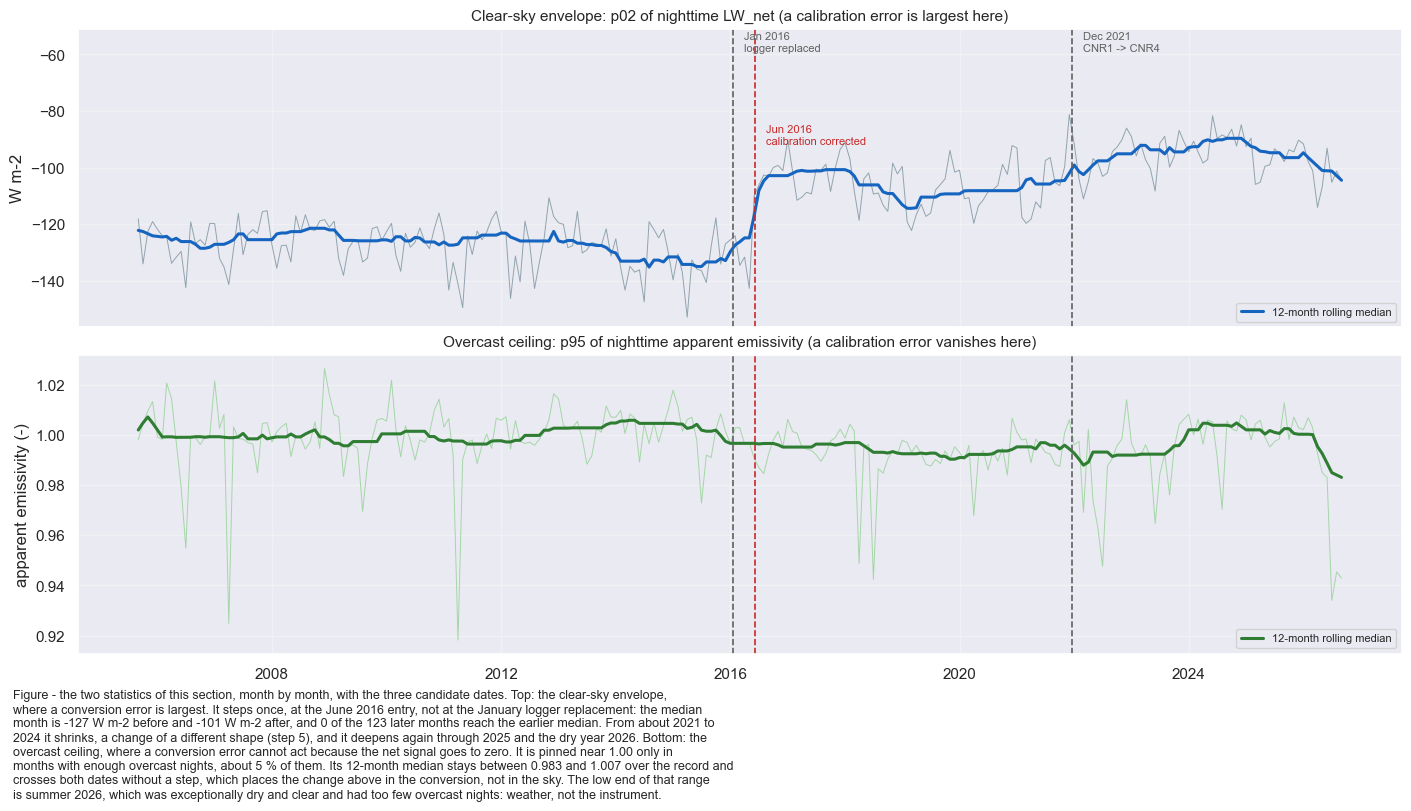

In [28]:
fig, axs = plt.subplots(nrows=2, figsize=(14, 8), dpi=100, layout='constrained', sharex=True)

# The two 2016 labels are staggered vertically so that they do not overlap.
_dates = [(pd.Timestamp(LOGGER_CHANGE), 'Jan 2016\nlogger replaced', '#616161', 0.99),
          (pd.Timestamp(CAL_CHANGE), 'Jun 2016\ncalibration corrected', '#C62828', 0.68),
          (pd.Timestamp(CNR4_INSTALLED), 'Dec 2021\nCNR1 -> CNR4', '#616161', 0.99)]

axs[0].plot(ENVELOPE_M.index, ENVELOPE_M.values, color='#90A4AE', lw=0.7)
axs[0].plot(ENVELOPE_M.index, ENVELOPE_M.rolling(12, center=True, min_periods=6).median(),
            color='#1565C0', lw=2.2, label='12-month rolling median')
axs[0].set_ylabel('W m-2')
axs[0].set_title(f'Clear-sky envelope: p{int(100 * CLEAR_Q):02d} of nighttime LW_net '
                 f'(a calibration error is largest here)', fontsize=11)
axs[0].legend(fontsize=8, loc='lower right')

_ceiling_m = monthly_q(EMIS_NIGHT, OVERCAST_Q)
axs[1].plot(_ceiling_m.index, _ceiling_m.values, color='#A5D6A7', lw=0.7)
axs[1].plot(_ceiling_m.index, _ceiling_m.rolling(12, center=True, min_periods=6).median(),
            color='#2E7D32', lw=2.2, label='12-month rolling median')
axs[1].set_ylabel('apparent emissivity (-)')
axs[1].set_title(f'Overcast ceiling: p{int(100 * OVERCAST_Q)} of nighttime apparent emissivity '
                 f'(a calibration error vanishes here)', fontsize=11)
axs[1].legend(fontsize=8, loc='lower right')

for _ax in axs:
    _ax.grid(alpha=0.3)
    for _d, _t, _c, _y in _dates:
        _ax.axvline(_d, color=_c, ls='--', lw=1.2)
_lo, _hi = axs[0].get_ylim()
axs[0].set_ylim(_lo, _hi + 0.34 * (_hi - _lo))
_lo, _hi = axs[0].get_ylim()
for _d, _t, _c, _y in _dates:
    axs[0].text(_d + pd.Timedelta(days=70), _lo + _y * (_hi - _lo), _t, fontsize=8,
                color=_c, va='top')

figcap(fig, f"the two statistics of this section, month by month, with the three candidate "
            f"dates. Top: the clear-sky envelope, where a conversion error is largest. It steps "
            f"once, at the June 2016 entry, not at the January logger replacement: the median month "
            f"is {ENVELOPE_M.loc[:'2016-05'].median():.0f} W m-2 before and "
            f"{ENVELOPE_M.loc['2016-07':].median():.0f} W m-2 after, and "
            f"{int((ENVELOPE_M.loc['2016-07':] < ENVELOPE_M.loc[:'2016-05'].median()).sum())} of "
            f"the {len(ENVELOPE_M.loc['2016-07':])} later months reach the earlier median. From "
            f"about 2021 to 2024 it shrinks, a change of a different shape (step 5), and it "
            f"deepens again through 2025 and the dry year 2026. Bottom: the "
            f"overcast ceiling, where a conversion error cannot act because the net signal goes to "
            f"zero. It is pinned near 1.00 only in months with enough overcast nights, about 5 % "
            f"of them. Its 12-month median stays between "
            f"{_ceiling_m.rolling(12, center=True, min_periods=6).median().min():.3f} and "
            f"{_ceiling_m.rolling(12, center=True, min_periods=6).median().max():.3f} over the "
            f"record and crosses both dates without a step, which places the change above in the "
            f"conversion, not in the sky. The low end of that range is summer 2026, which was "
            f"exceptionally dry and clear and had too few overcast nights: weather, not the "
            f"instrument.")

#### 📊 Plot: emissivity distribution per calibration era

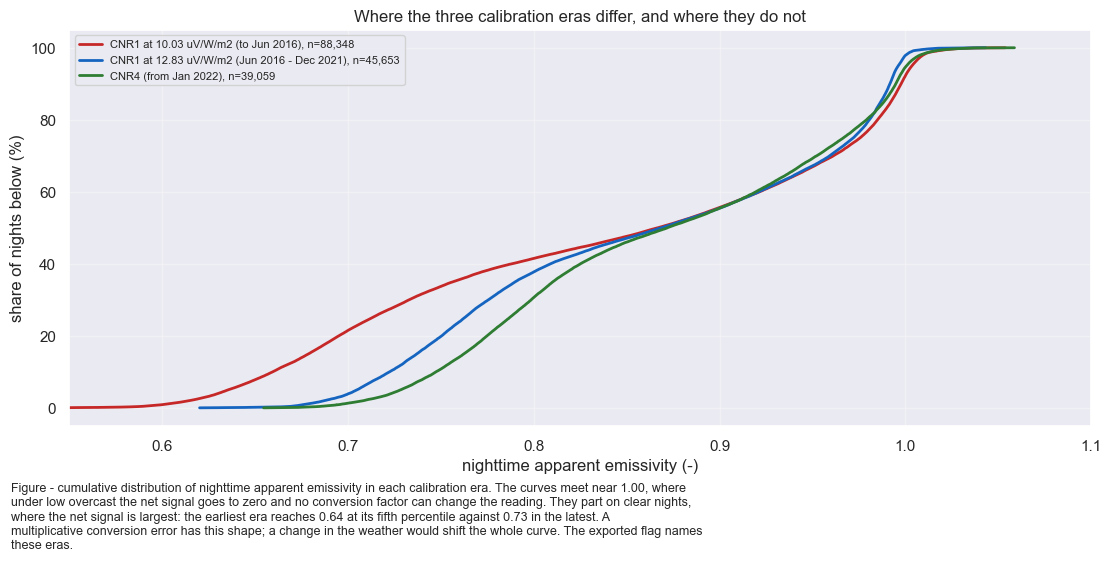

In [29]:
# The same finding as a distribution rather than as a percentile. A multiplicative error on LW_net
# compresses the whole emissivity distribution towards 1 and leaves its upper end where it was.
fig, ax = plt.subplots(figsize=(11, 5.5), dpi=100, layout='constrained')
ERAS = [(f'CNR1 at {SENSITIVITY_OLD} uV/W/m2 (to Jun 2016)', slice(None, '2016-06-06'), '#C62828'),
        (f'CNR1 at {SENSITIVITY_NEW} uV/W/m2 (Jun 2016 - Dec 2021)',
         slice('2016-06-07', '2021-12-14'), '#1565C0'),
        ('CNR4 (from Jan 2022)', slice('2022-01-07', None), '#2E7D32')]
_p05 = {}
for _label, _sl, _colour in ERAS:
    _e = EMIS_NIGHT.loc[_sl].dropna().sort_values()
    _p05[_label] = float(_e.quantile(0.05))
    ax.plot(_e.values, np.linspace(0, 100, len(_e)), color=_colour, lw=2.0,
            label=f'{_label}, n={len(_e):,}')
ax.set_xlabel('nighttime apparent emissivity (-)')
ax.set_ylabel('share of nights below (%)')
ax.set_xlim(0.55, 1.10)
ax.set_title('Where the three calibration eras differ, and where they do not', fontsize=12)
ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc='upper left')
figcap(fig, "cumulative distribution of nighttime apparent emissivity in each calibration era. "
            "The curves meet near 1.00, where under low overcast the net signal goes to zero and no "
            "conversion factor can change the reading. They part on clear nights, where the net "
            f"signal is largest: the earliest era reaches {min(_p05.values()):.2f} at its fifth "
            f"percentile against {max(_p05.values()):.2f} in the latest. A multiplicative "
            "conversion error has this shape; a change in the weather would shift the whole curve. "
            "The exported flag names these eras.")

::: {.callout-important title="The exported series is not homogeneous across 7 June 2016"}
Values before that date use a factor 28 % too small and **read low**, in proportion to how clear the
sky was. At the 17 % measured in step 3, that is about 8 W m-2 at the median of nighttime `LW_net`
before the change and up to some 23 W m-2 at its 2nd percentile, a clear, dry night. Later values
use the instrument's own calibration.

This is **not corrected**. Undoing it means splitting each value into instrument emission and net
signal, which needs the radiometer's **body temperature**. This product does not read that channel,
and its treatment in the processing chain of that era cannot be verified from the available files.
Air temperature as a proxy would import an unverified model of that chain into the exported values.

Instead a **`SOURCE` flag names the calibration era**, and the size and shape of the offset are
recorded here and on the documentation page. Users with the raw voltages or the body temperature can
apply the correction; users of this product alone should filter on the flag.
:::

### 4️⃣ The January 2016 acquisition change did nothing

Two independent results show this. The program installed at the changeover carries the **same**
multiplier as the CR10X programs (step 1). And February to May 2016, new logger with old factor,
lies inside the quiet-year range of the statistic that puts July to December 2016 far outside it.

The two dates are five months apart. Placing the break in January puts it in the wrong quarter and
wrongly aligns it with the `TA` break.

### 5️⃣ The December 2021 boundary

Two candidate causes coincide: the radiometer replacement on 14 December 2021 and the end of the
`mst` screening on 31 December 2021. Unlike `01`, there is no external reference, only the same
physics.

The median rises from about 316 W m-2 over 2019-2021 to about 326 over 2022-2024. The question is
how much of that is weather, and whether the rest is a step at the boundary or a slower change.

#### 📋 Table: level change across December 2021

In [30]:
# Step one: how much of the level change does temperature alone account for? The sensitivity is
# derived from the record's own emissivity and mean temperature rather than assumed.
PERIOD_BEFORE, PERIOD_AFTER = ('2019', '2021'), ('2022', '2024')
_emis_ref = float(EMIS_NIGHT.loc['2006':'2020'].median())
_tmean = float(TA_DIAG.where(TA_IS_MEASURED).loc['2006':'2021'].mean()) + 273.15
DLW_DTA = 4 * _emis_ref * SIGMA * _tmean ** 3

_lw_a = float(LW_FINAL.loc[PERIOD_BEFORE[0]:PERIOD_BEFORE[1]].median())
_lw_b = float(LW_FINAL.loc[PERIOD_AFTER[0]:PERIOD_AFTER[1]].median())
_ta = TA_DIAG.where(TA_IS_MEASURED)
_ta_a = float(_ta.loc[PERIOD_BEFORE[0]:PERIOD_BEFORE[1]].mean())
_ta_b = float(_ta.loc[PERIOD_AFTER[0]:PERIOD_AFTER[1]].mean())

tabcap("the level change across December 2021, and the part that the temperature difference "
       "explains through the Stefan-Boltzmann relation. The residual is the subject of this step")
display(pd.DataFrame({
    'LW_IN median (W m-2)': [round(_lw_a, 2), round(_lw_b, 2), round(_lw_b - _lw_a, 2)],
    'TA mean (degC)': [round(_ta_a, 3), round(_ta_b, 3), round(_ta_b - _ta_a, 3)],
}, index=[f'{PERIOD_BEFORE[0]}-{PERIOD_BEFORE[1]}', f'{PERIOD_AFTER[0]}-{PERIOD_AFTER[1]}',
          'difference']))

_predicted = (_ta_b - _ta_a) * DLW_DTA
_residual = (_lw_b - _lw_a) - _predicted
print(f"dLW/dTA at this site: {DLW_DTA:.2f} W m-2 per K")
print(f"observed change   {_lw_b - _lw_a:+.2f} W m-2")
print(f"temperature alone {_predicted:+.2f} W m-2   ->  residual {_residual:+.2f} W m-2")
print("\nSo temperature accounts for about "
      f"{100 * _predicted / (_lw_b - _lw_a):.0f} % of the level change and not for the rest. "
      "That does not make the rest an instrument effect: a warmer atmosphere is also a moister "
      "one, and both raise the sky's emissivity. The tests below ask the different question of "
      "whether anything happens AT the boundary.")

Table - the level change across December 2021, and the part that the temperature difference explains
through the Stefan-Boltzmann relation. The residual is the subject of this step



,LW_IN median (W m-2),TA mean (degC)
2019-2021,316.32,9.849
2022-2024,326.01,10.565
difference,9.69,0.715


dLW/dTA at this site: 4.43 W m-2 per K
observed change   +9.69 W m-2
temperature alone +3.17 W m-2   ->  residual +6.52 W m-2

So temperature accounts for about 33 % of the level change and not for the rest. That does not make the rest an instrument effect: a warmer atmosphere is also a moister one, and both raise the sky's emissivity. The tests below ask the different question of whether anything happens AT the boundary.


#### 📋 Table: December 2021 against June 2016

In [31]:
# Step two: does anything happen AT the boundary? The same month-matched statistic as at June 2016,
# on the first half of 2022 against the first half of the three preceding years.
SCREENING_YEAR = 2022
_quiet_first = placebo_ratios(ENVELOPE_M, FIRSTHALF, BOUNDARIES)
DEC2021_TEST = matched_ratio(ENVELOPE_M, FIRSTHALF, [2019, 2020, 2021], [SCREENING_YEAR])

tabcap("the December 2021 boundary measured as at June 2016, beside it. The quiet-year range is "
       "the same statistic at every year whose window holds neither boundary")
_cmp = pd.DataFrame({
    f'Jan-Jun {SCREENING_YEAR} against {SCREENING_YEAR - 3}-{SCREENING_YEAR - 1}': DEC2021_TEST,
    'Jul-Dec 2016 against 2013-2015': JUN2016_TEST,
}).T
_cmp['quiet-year range'] = [f'{_quiet_first.min():.3f} - {_quiet_first.max():.3f}',
                            f'{_quiet_autumn.min():.3f} - {_quiet_autumn.max():.3f}']
display(_cmp)

print(f"The December 2021 boundary does move this statistic, and by more than a quiet year does. "
      f"It moves it by about half as much as the calibration change did: "
      f"{100 * (1 - DEC2021_TEST['ratio']):.0f} % against "
      f"{100 * (1 - JUN2016_TEST['ratio']):.0f} %.")

assert DEC2021_TEST['ratio'] > JUN2016_TEST['ratio'], (
    "the December 2021 boundary now moves the clear-sky envelope by more than the June 2016 "
    "calibration change did, which would make it the larger of the two events and would need a "
    "different treatment than the one this notebook gives it")

Table - the December 2021 boundary measured as at June 2016, beside it. The quiet-year range is the
same statistic at every year whose window holds neither boundary



,months compared,before (W m-2),after (W m-2),ratio,quiet-year range
Jan-Jun 2022 against 2019-2021,18 vs 6,-113.9,-101.3,0.8893,0.956 - 1.077
Jul-Dec 2016 against 2013-2015,18 vs 6,-127.2,-101.9,0.8006,0.979 - 1.039


The December 2021 boundary does move this statistic, and by more than a quiet year does. It moves it by about half as much as the calibration change did: 11 % against 20 %.


#### 📋 Table: shape of the two changes and a quiet interval

In [32]:
# Step three: can the change be identified? A conversion factor scales every percentile of the
# tail by one number, as at June 2016. The pinned ceiling, which it cannot move, is shown too.
# Yearly values stop at LAST_FULL_YEAR (see yearly_q).
_QS = (0.01, 0.02, 0.05, 0.10, 0.20)


def era_ratios(before, after):
    return pd.Series({f'p{int(100 * _q):02d}': float(
        yearly_q(LWNET_NIGHT, _q).loc[after[0]:after[1]].mean()
        / yearly_q(LWNET_NIGHT, _q).loc[before[0]:before[1]].mean()) for _q in _QS})


_LAB_2021 = f'across Dec 2021 (2022-{LAST_FULL_YEAR} / 2017-2021)'
_shape = pd.DataFrame({
    'across June 2016 (2017-2021 / 2006-2015)': era_ratios((2006, 2015), (2017, 2021)),
    _LAB_2021: era_ratios((2017, 2021), (2022, LAST_FULL_YEAR)),
    'a quiet interval (2012-2015 / 2007-2011)': era_ratios((2007, 2011), (2012, 2015)),
}).T
_shape['spread across percentiles'] = (_shape[[f'p{int(100 * _q):02d}' for _q in _QS]]
                                       .max(axis=1) - _shape[[f'p{int(100 * _q):02d}' for _q in _QS]]
                                       .min(axis=1)).round(4)
_shape['clear-sky change (%)'] = (100 * (_shape[[f'p{int(100 * _q):02d}' for _q in _QS]]
                                         .mean(axis=1) - 1)).round(2)
_shape['overcast ceiling change (%)'] = [round(step_at(CEILING_Y, 2016), 2),
                                         round(step_at(CEILING_Y, SCREENING_YEAR), 2),
                                         round(step_at(CEILING_Y, 2013), 2)]
tabcap("the shape of each change rather than its size. The last two columns show whether a change "
       "is confined to the clear-sky end: both real changes move the clear-sky envelope by ten to "
       "twenty times what they move the pinned overcast ceiling. The spread column shows whether "
       "one factor describes the whole clear-sky tail: at June 2016 it does, at December 2021 no "
       "better than in a quiet interval")
display(_shape.round(4))

_spread_2016 = float(_shape.loc['across June 2016 (2017-2021 / 2006-2015)', 'spread across percentiles'])
_spread_2021 = float(_shape.loc[_LAB_2021, 'spread across percentiles'])
print(f"spread across percentiles: June 2016 {_spread_2016:.4f}, December 2021 {_spread_2021:.4f}")
for _row in _shape.index[:2]:
    _clear, _ceil = abs(_shape.loc[_row, 'clear-sky change (%)']), abs(_shape.loc[_row, 'overcast ceiling change (%)'])
    print(f"  {_row}: clear-sky {_clear:.1f} % against overcast ceiling {_ceil:.2f} %, "
          f"a factor of {_clear / _ceil:.0f}")
    assert _clear > 5 * _ceil, (
        f"{_row}: the change is no longer concentrated at the clear-sky end of the distribution, "
        f"which is where a conversion error acts and nowhere else")

assert _spread_2016 < _spread_2021, (
    "the December 2021 change is now as cleanly multiplicative as the June 2016 one, which would "
    "make it identifiable as a conversion change and would change what this section concludes")
assert abs(step_at(CEILING_Y, SCREENING_YEAR)) < 1.0, (
    "the overcast ceiling now moves at the December 2021 boundary by as much as an ordinary "
    "change in the clear-sky end. It is pinned by physics, so a change in it would be a change in "
    "the measurement under overcast, which no conversion factor can produce")
print("\nBoth changes sit at the clear-sky end and barely touch the overcast ceiling, which is "
      "what keeps both of them inside the part of the signal a conversion error can reach. Only "
      "one of them is described by a single factor.")

Table - the shape of each change rather than its size. The last two columns show whether a change is
confined to the clear-sky end: both real changes move the clear-sky envelope by ten to twenty times
what they move the pinned overcast ceiling. The spread column shows whether one factor describes the
whole clear-sky tail: at June 2016 it does, at December 2021 no better than in a quiet interval



,p01,p02,p05,p10,p20,spread across percentiles,clear-sky change (%),overcast ceiling change (%)
across June 2016 (2017-2021 / 2006-2015),0.8272,0.8304,0.8282,0.8232,0.8204,0.0100,-17.41,-1.02
across Dec 2021 (2022-2025 / 2017-2021),0.8983,0.8949,0.8974,0.9078,0.9313,0.0365,-9.40,0.48
a quiet interval (2012-2015 / 2007-2011),1.0353,1.0292,1.0214,1.0191,1.0003,0.0350,2.11,0.13


spread across percentiles: June 2016 0.0100, December 2021 0.0365
  across June 2016 (2017-2021 / 2006-2015): clear-sky 17.4 % against overcast ceiling 1.02 %, a factor of 17
  across Dec 2021 (2022-2025 / 2017-2021): clear-sky 9.4 % against overcast ceiling 0.48 %, a factor of 20

Both changes sit at the clear-sky end and barely touch the overcast ceiling, which is what keeps both of them inside the part of the signal a conversion error can reach. Only one of them is described by a single factor.


::: {.callout-important title="December 2021: a change this notebook cannot attribute"}
The record moves across the boundary, by most of the residual left after temperature. Three causes
cannot be separated with these data:

- **the instrument.** The CNR4 replaced the CNR1 on 14 December 2021. Its longwave factor is
  10.85 µV/W/m², against the 12.83 the CNR1 had from June 2016.
- **the screening.** `mst` ends on 31 December 2021 and `diive` begins on 1 January 2022, with no
  overlap.
- **the atmosphere.** The clear-sky end of the record follows the temperature and humidity of the
  lower atmosphere. It shrank from 2019 to 2024, the direction a warmer, moister atmosphere would
  cause, and deepened again through 2025 and the dry year 2026. A gradual change of this kind
  cannot be separated from a step at the boundary.

At June 2016 one factor scaled the whole clear-sky tail and the fieldbook named it. Here the ratio
across the tail is no steadier than in a quiet interval, and the fieldbook records the replacement
but no reprocessing.

`SW_IN`, from the same radiometer, does not step across December 2021 against two independent
references (notebook `01`). That excludes a common-mode fault in wiring, logger or acquisition, but
not a change in the pyrgeometer, a separate detector with its own calibration.

**Nothing is corrected**: correcting an unattributed change would replace a measurement with a
guess, as `01` and `03` conclude for their drifts. The `SOURCE` flag separates the two instruments.
:::

#### What this section settles

The four findings listed at the start of this section hold. The break of **7 June 2016** lies
mid-record, is larger than anything at either hardware date, and is the main point for users. The
series is **homogeneous across January 2016**, and **December 2021** moves it by about half as much
as June 2016, for no identifiable cause.

None of these is corrected: June 2016 needs a channel this product lacks, and December 2021 has no
known cause. The export carries the measured series and the era flag. The assertions fail the run
if the June 2016 step disappears, if a step appears between the two 2016 dates, or if December 2021
becomes the larger event.

***

## 🏷️ Provenance flag: which instrument and which calibration

One column name spans two instruments and three calibration factors, so the file names the source of
each value, using the dates derived above (two from the fieldbook, one from the logger program it
records).

The changeover has **its own code**. The CNR4 was installed on 14 December 2021, but its constants
reached the program only on 7 January 2022, so for three weeks it was read with the old factor.
Neither fieldbook nor data can narrow this, so the interval is marked undetermined, as `08` does for
its 71-day 2018 transition.

### 📋 Table: provenance flag by code

In [33]:
FLAGCOL = f'FLAG_{TARGET}_SOURCE'
# Written with inclusive end dates, so the legend reads the way a data user would filter.
_last_cnr1 = (pd.Timestamp(CNR4_INSTALLED) - pd.Timedelta(days=1)).date()
_last_undet = (pd.Timestamp(CNR4_CONSTANTS) - pd.Timedelta(days=1)).date()
_last_old_cal = (pd.Timestamp(CAL_CHANGE) - pd.Timedelta(days=1)).date()
SOURCE_LEGEND = {
    0: f'0 = CNR4 on its own calibration factor (from {CNR4_CONSTANTS})',
    1: f"1 = CNR1 at {SENSITIVITY_NEW} uV/W/m2, the pyrgeometer's own factor ({CAL_CHANGE} to "
       f'{_last_cnr1})',
    2: f'2 = CNR1 at {SENSITIVITY_OLD} uV/W/m2, the PYRANOMETER factor - reads low (to '
       f'{_last_old_cal})',
    3: f'3 = changeover, era undetermined ({CNR4_INSTALLED} to {_last_undet}): CNR4 installed, '
       f'CNR1 constants still in the program',
}

source = pd.Series(0, index=full_index, dtype='int8', name=FLAGCOL)
source.loc[:pd.Timestamp(CAL_CHANGE) - pd.Timedelta(minutes=15)] = 2
source.loc[pd.Timestamp(CAL_CHANGE):pd.Timestamp(CNR4_INSTALLED) - pd.Timedelta(minutes=15)] = 1
source.loc[pd.Timestamp(CNR4_INSTALLED):pd.Timestamp(CNR4_CONSTANTS) - pd.Timedelta(minutes=15)] = 3
# code 0 is what remains, from CNR4_CONSTANTS onwards

tabcap("the exported provenance flag by code. Code 2, the era that reads low, is about half the "
       "record; code 3 is the three weeks the evidence cannot assign to either instrument")
_flagtab = pd.DataFrame({
    'meaning': {c: SOURCE_LEGEND[c] for c in sorted(SOURCE_LEGEND)},
    'records': source.value_counts().reindex(sorted(SOURCE_LEGEND)).astype(int),
    'measured records': source.where(lw_2005_2026[TARGET].notna()).value_counts()
                              .reindex(sorted(SOURCE_LEGEND)).fillna(0).astype(int),
})
_flagtab['share of measured (%)'] = (100 * _flagtab['measured records']
                                     / _flagtab['measured records'].sum()).round(2)
_flagtab.index.name = 'code'
with pd.option_context('display.max_colwidth', 130):
    display(_flagtab)

# The flag covers the whole index once, and its boundaries are the dates derived above.
assert source.notna().all(), "the source flag is not defined everywhere"
assert set(source.unique()) == set(SOURCE_LEGEND), \
    "a code appears in the flag that the legend does not describe, or the other way round"
assert source.loc[:'2016-06-06 23:45'].eq(2).all() and source.loc['2016-06-07 00:15':'2021-12-14 23:45'].eq(1).all(), \
    "the two CNR1 eras no longer meet exactly at the calibration change"
assert int(source.eq(3).sum()) == len(pd.date_range(f'{CNR4_INSTALLED} 00:15',
                                                    pd.Timestamp(CNR4_CONSTANTS) - pd.Timedelta(minutes=15),
                                                    freq='30min')), \
    "the undetermined interval is not the interval between the two December/January dates"

Table - the exported provenance flag by code. Code 2, the era that reads low, is about half the
record; code 3 is the three weeks the evidence cannot assign to either instrument



,meaning,records,measured records,share of measured (%)
code,,,,
0,0 = CNR4 on its own calibration factor (from 2022-01-07),82944,82828,22.75
1,"1 = CNR1 at 12.83 uV/W/m2, the pyrgeometer's own factor (2016-06-07 to 2021-12-14)",96816,96037,26.38
2,"2 = CNR1 at 10.03 uV/W/m2, the PYRANOMETER factor - reads low (to 2016-06-06)",188112,184104,50.57
3,"3 = changeover, era undetermined (2021-12-15 to 2022-01-06): CNR4 installed, CNR1 constants still in the program",1104,1104,0.30


***

## 🚫 No gap-filling here

As in notebook `05`, the series is exported as measured:

- `LW_IN_T1_47_1` **contains `NaN`**; code assuming a complete series will fail or propagate it.
- There is **no `FLAG_..._ISFILLED` column**. Non-null means measured.
- A complete series, if needed, should be filled and flagged downstream. `LW_IN` is smooth and tied
  to air temperature and cloudiness, but a fill must respect the calibration eras the flag names
  rather than train one model across them.

***

## ➡️ Prepare dataframe for export

### 📋 Table: the exported frame

In [34]:
VALCOL = TARGET

export_df = lw_2005_2026[[VALCOL]].copy()
export_df[FLAGCOL] = source
tabcap("the exported frame: the measured series and the flag naming the instrument and calibration "
       "factor behind each value")
display(export_df)

Table - the exported frame: the measured series and the flag naming the instrument and calibration
factor behind each value



,LW_IN_T1_47_1,FLAG_LW_IN_T1_47_1_SOURCE
TIMESTAMP_MIDDLE,,
2005-09-14 00:15:00,NaN,2
2005-09-14 00:45:00,NaN,2
2005-09-14 01:15:00,NaN,2
2005-09-14 01:45:00,NaN,2
2005-09-14 02:15:00,NaN,2
...,...,...
2026-09-30 21:45:00,355.379570,0
2026-09-30 22:15:00,353.670990,0
2026-09-30 22:45:00,359.867010,0


Sanity check. The series is **not** expected to be complete, so the check is that the index is
sound and ends at `PERIOD_END`, every value is plausible longwave, and the flag is defined at every
record.

### 📋 Table: summary statistics of the export

In [35]:
_lo, _hi = LW_IN_PLAUSIBLE_WM2

print(f"Records:          {len(export_df):,}")
print(f"Measured:         {int(export_df[VALCOL].notna().sum()):,} "
      f"({100 * export_df[VALCOL].notna().mean():.2f}%)")
print(f"Missing (NaN):    {int(export_df[VALCOL].isnull().sum()):,} "
      f"({100 * export_df[VALCOL].isna().mean():.2f}%)")
print(f"Duplicate index:  {int(export_df.index.duplicated().sum())}")
print(f"Index gaps:       "
      f"{int((export_df.index.to_series().diff().dropna() != pd.Timedelta('30min')).sum())}")
print(f"Index:            {export_df.index[0]} -> {export_df.index[-1]}")
print(f"Min / max:        {export_df[VALCOL].min():.2f} / {export_df[VALCOL].max():.2f} W m-2")

assert export_df.index.duplicated().sum() == 0, "duplicate timestamps"
assert (export_df.index.to_series().diff().dropna() == pd.Timedelta('30min')).all(), \
    "index not continuous 30MIN"
assert export_df[VALCOL].min() >= _lo and export_df[VALCOL].max() <= _hi, \
    f"values outside {_lo}-{_hi} W m-2"
assert export_df[VALCOL].notna().any(), "no data at all"
assert export_df[FLAGCOL].notna().all(), "the provenance flag is not defined at every record"
assert export_df.index[-1] == pd.Timestamp(PERIOD_END), (
    f"the export ends at {export_df.index[-1]}, not at PERIOD_END ({PERIOD_END})")
print("\nAll checks passed.")

tabcap("summary statistics of the exported value column")
display(export_df[[VALCOL]].describe())

Records:          368,976
Measured:         364,073 (98.67%)
Missing (NaN):    4,903 (1.33%)
Duplicate index:  0
Index gaps:       0
Index:            2005-09-14 00:15:00 -> 2026-09-30 23:45:00
Min / max:        135.45 / 441.78 W m-2

All checks passed.
Table - summary statistics of the exported value column



,LW_IN_T1_47_1
count,364073.000000
mean,311.011331
std,45.546419
min,135.445129
25%,282.811035
50%,316.153171
75%,343.784620
max,441.779694


### Per-year statistics

`coverage_%` shows the real gaps: the removed 2012 fault periods, and sensor outages in 2009, 2016
and 2019. 2005 (from 14 September) and 2026 (to 30 September) are marked partial; their medians are
not comparable with full years.

`calibration` gives the flag codes in each year. The level rises across both boundaries: the first
rise is a correction of the conversion, the second cannot be attributed.

#### 📋 Table: the export year by year

In [36]:
_yr = export_df[VALCOL].groupby(export_df.index.year).agg(['count', 'median', 'min', 'max', 'std'])
_yr['possible'] = export_df[VALCOL].groupby(export_df.index.year).size()
_yr['coverage_%'] = (100 * _yr['count'] / _yr['possible']).round(2)
_yr['calibration'] = (export_df[FLAGCOL].groupby(export_df.index.year)
                      .agg(lambda s: '/'.join(str(int(v)) for v in sorted(s.unique()))))
# The first year starts at RECORD_START and years after LAST_FULL_YEAR end at PERIOD_END; their
# medians are not comparable with full years.
_yr['note'] = ''
_yr.loc[_yr.index.min(), 'note'] = f'partial (from {pd.Timestamp(RECORD_START):%d %b})'
_yr.loc[_yr.index > LAST_FULL_YEAR, 'note'] = f'partial (to {pd.Timestamp(PERIOD_END):%d %b})'
tabcap("the exported series year by year. `calibration` gives the flag codes present in each year, "
       "so the two years holding a boundary carry more than one code. `note` marks partial years")
display(_yr.round(2))

_med = _yr['median']
assert ((_med > _lo) & (_med < _hi)).all(), "a yearly median is outside the plausible band"
print(f"All yearly medians between {_med.min():.2f} and {_med.max():.2f} W m-2.")
_med_full = _med.loc[2006:LAST_FULL_YEAR]
print(f"Full-year medians (2006-{LAST_FULL_YEAR}) span {_med_full.min():.2f} to "
      f"{_med_full.max():.2f} W m-2, sd {_med_full.std():.2f}.")

Table - the exported series year by year. `calibration` gives the flag codes present in each year,
so the two years holding a boundary carry more than one code. `note` marks partial years



,count,median,min,max,std,possible,coverage_%,calibration,note
TIMESTAMP_MIDDLE,,,,,,,,,
2005,5184,296.53,166.98,387.15,44.45,5232,99.08,2,partial (from 14 Sep)
2006,17396,311.56,160.44,415.70,50.49,17520,99.29,2,
2007,17422,310.10,164.10,411.22,46.83,17520,99.44,2,
2008,17423,312.23,164.83,410.42,49.23,17568,99.17,2,
2009,16917,307.12,149.90,414.92,46.90,17520,96.56,2,
2010,17291,307.81,149.98,420.89,47.11,17520,98.69,2,
2011,17472,308.11,170.92,411.45,47.08,17520,99.73,2,
2012,16210,314.01,135.45,419.37,50.73,17568,92.27,2,
2013,17362,311.62,169.86,441.78,45.75,17520,99.10,2,


All yearly medians between 296.53 and 329.94 W m-2.
Full-year medians (2006-2025) span 307.12 to 329.94 W m-2, sd 6.43.


#### 📊 Plot: heatmap and per-year level of the export

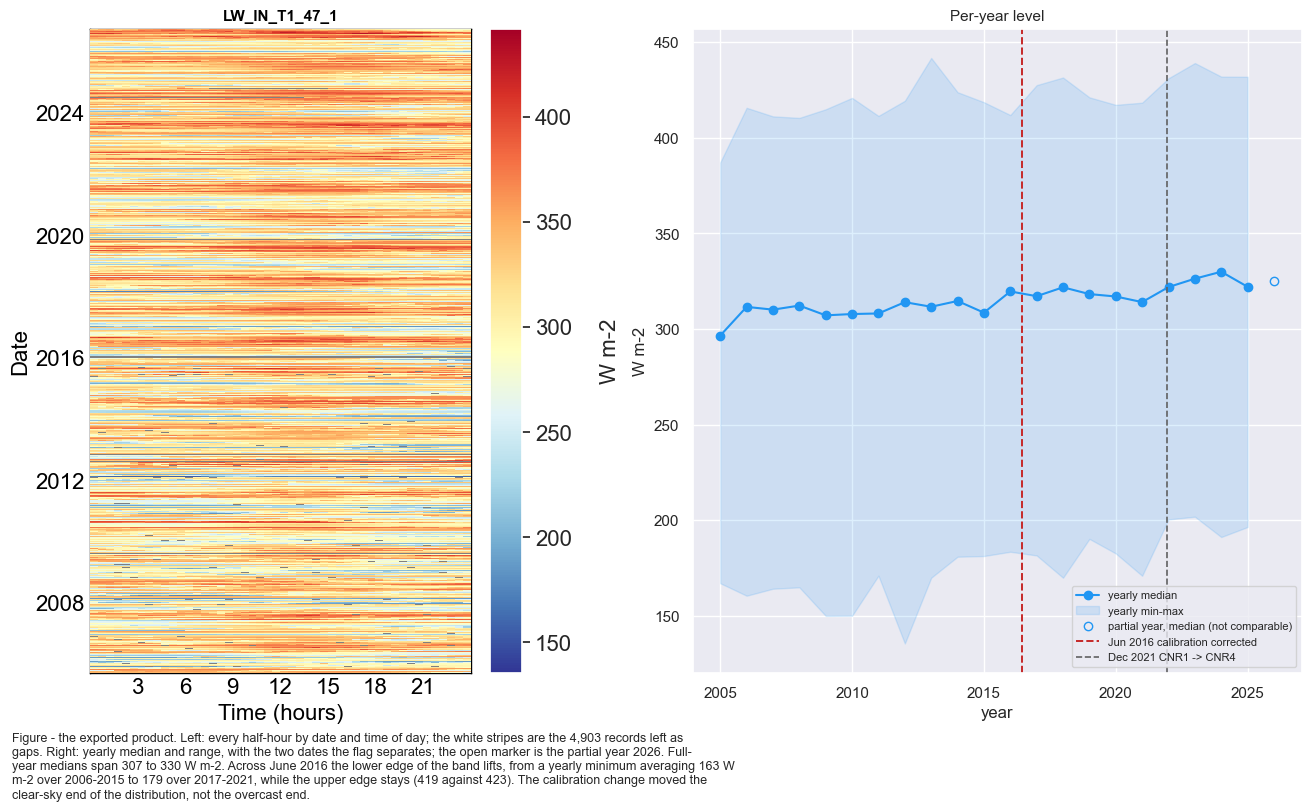

In [37]:
fig, axs = plt.subplots(ncols=2, figsize=(13, 8), dpi=100, layout='constrained',
                        width_ratios=[1, 1.6])
dv.plotting.HeatmapDateTime(series=export_df[VALCOL]).plot(
    ax=axs[0], cb_digits_after_comma=0, zlabel='W m-2',
    format_style=dv.plotting.FormatStyle(title=VALCOL, title_fontsize=11))

# Full years as line and band; the partial last year as an open marker, not joined to them.
_full, _part = _yr.loc[:LAST_FULL_YEAR], _yr.loc[LAST_FULL_YEAR + 1:]
_full['median'].plot(ax=axs[1], marker='o', color='#2196F3', label='yearly median')
axs[1].fill_between(_full.index, _full['min'], _full['max'], color='#2196F3', alpha=.15,
                    label='yearly min-max')
axs[1].plot(_part.index, _part['median'], 'o', mfc='none', color='#2196F3',
            label='partial year, median (not comparable)')
axs[1].axvline(2016.44, color='#C62828', ls='--', lw=1.4, label='Jun 2016 calibration corrected')
axs[1].axvline(2021.96, color='#616161', ls='--', lw=1.2, label='Dec 2021 CNR1 -> CNR4')
axs[1].set_ylabel('W m-2')
axs[1].set_xlabel('year')
axs[1].set_title('Per-year level', fontsize=11)
axs[1].legend(fontsize=8)

_min_before = float(_yr.loc[2006:2015, 'min'].mean())
_min_after = float(_yr.loc[2017:2021, 'min'].mean())
_max_before = float(_yr.loc[2006:2015, 'max'].mean())
_max_after = float(_yr.loc[2017:2021, 'max'].mean())
figcap(fig, f"the exported product. Left: every half-hour by date and time of day; the white "
            f"stripes are the {int(export_df[VALCOL].isna().sum()):,} records left as gaps. Right: "
            f"yearly median and range, with the two dates the flag separates; the open marker is "
            f"the partial year {pd.Timestamp(PERIOD_END).year}. Full-year medians span "
            f"{_med_full.min():.0f} to {_med_full.max():.0f} W m-2. Across June 2016 the lower edge "
            f"of the band lifts, from a yearly minimum averaging {_min_before:.0f} W m-2 over "
            f"2006-2015 to {_min_after:.0f} over 2017-2021, while the upper edge stays "
            f"({_max_before:.0f} against {_max_after:.0f}). The calibration change moved the "
            f"clear-sky end of the distribution, not the overcast end.")

***

## 💾 Save to file

In [38]:
filepath = dv.save_parquet(filename=OUTNAME, data=export_df, outpath=OUTPATH)
export_df.to_csv(Path(OUTPATH) / f"{OUTNAME}.csv")
print(f"Saved to: {filepath}")

> Saved file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODU
CTS\06_METEO_LW_IN_2005-2026.09.parquet (0.116 seconds).

Saved to: F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODUCTS\06_METEO_LW_IN_2005-2026.09.parquet


### Verify the written file

The parquet is read back and checked directly.

#### 📋 Table: yearly median per flag code, from the written file

In [39]:
_written = dv.load_parquet(filepath=str(Path(OUTPATH) / f"{OUTNAME}.parquet"))

print(f"columns:   {list(_written.columns)}")
print(f"index:     {_written.index[0]} -> {_written.index[-1]}  ({len(_written):,} records)")
print(f"measured:  {int(_written[VALCOL].notna().sum()):,} "
      f"({100 * _written[VALCOL].notna().mean():.2f}%)")
print(f"median:    {float(_written[VALCOL].median()):.2f} W m-2")
print(f"min / max: {float(_written[VALCOL].min()):.2f} / {float(_written[VALCOL].max()):.2f} W m-2")

assert list(_written.columns) == [VALCOL, FLAGCOL], "unexpected columns in the written file"
assert len(_written) == len(export_df), "record count changed on write"
assert _written[VALCOL].notna().sum() == export_df[VALCOL].notna().sum(), \
    "measured count changed on write"
assert _written[FLAGCOL].equals(export_df[FLAGCOL]), "the provenance flag changed on write"
assert _lo < float(_written[VALCOL].median()) < _hi, "median outside plausible range"
assert _written.index[-1] == pd.Timestamp(PERIOD_END), "the written file does not end at PERIOD_END"
print("\nWritten file verified.")

tabcap("the written file read back: median by year and calibration era, partial years marked")
_check = _written.groupby([_written.index.year, _written[FLAGCOL]])[VALCOL].median().unstack()
_check.index = pd.Index([f'{_y} (partial)' if (_y == _check.index.min() or _y > LAST_FULL_YEAR)
                         else str(_y) for _y in _check.index], name='YEAR')
_check.columns = [f'code {int(c)}' for c in _check.columns]
display(_check.round(2))

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODU
CTS\06_METEO_LW_IN_2005-2026.09.parquet (0.015 seconds).

columns:   ['LW_IN_T1_47_1', 'FLAG_LW_IN_T1_47_1_SOURCE']
index:     2005-09-14 00:15:00 -> 2026-09-30 23:45:00  (368,976 records)
measured:  364,073 (98.67%)
median:    316.15 W m-2
min / max: 135.45 / 441.78 W m-2

Written file verified.
Table - the written file read back: median by year and calibration era, partial years marked



,code 0,code 1,code 2,code 3
YEAR,,,,
2005 (partial),NaN,NaN,296.53,NaN
2006,NaN,NaN,311.56,NaN
2007,NaN,NaN,310.10,NaN
2008,NaN,NaN,312.23,NaN
2009,NaN,NaN,307.12,NaN
2010,NaN,NaN,307.81,NaN
2011,NaN,NaN,308.11,NaN
2012,NaN,NaN,314.01,NaN
2013,NaN,NaN,311.62,NaN


***

## End of notebook.

In [40]:
NOTEBOOK_END = datetime.now()
_h, _rem = divmod(int((NOTEBOOK_END - NOTEBOOK_START).total_seconds()), 3600)
_m, _s = divmod(_rem, 60)

print(f"Started:  {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Finished: {NOTEBOOK_END.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Runtime:  {_h:02d}:{_m:02d}:{_s:02d} (hh:mm:ss)")

Started:  2026-10-23 12:41:29
Finished: 2026-10-23 12:41:56
Runtime:  00:00:26 (hh:mm:ss)
